# HAM10000 Skin Lesion Classification (AID427 Final Project)

**Team:** Nasser Hossam Hamed (320230051), Mariam Ahmed Shawky (320230056) and Ammar Yasser (320230031), Section 1
**Dataset:** HAM10000, 10,015 dermatoscopic images of 7 skin-lesion classes (nv, mel, bkl, bcc, akiec, vasc, df) plus age, sex and lesion location. Source: Kaggle `kmader/skin-cancer-mnist-ham10000`.
**Goal:** classify the lesion type; Phase 1 grades dimensionality reduction, feature selection, metaheuristics and model evaluation.

## Map of this notebook

| Section | What it does | Phase 1 sheet item | Files saved to Drive (`ham10000_processed/`) |
|---|---|---|---|
| Part A: Setup | Mount Drive, find and copy the dataset | none | none |
| Part B: Preprocessing | 70/15/15 lesion-level split, resize images to 128x128 | Data analysis and preprocessing | `images_128.npy`, `meta_processed.csv` |
| Part C: Deep-learning reference study | Metadata baseline, ResNet18, image + metadata fusion | Reference for comparison | `resnet18_best.pt`, `fusion_best.pt` |
| Phase 1, Step 1 | New 80/20 lesion-level split, flattened features, EDA | Data visualization and analysis | `features_phase1.npz`, `meta_phase1.csv`, `eda_*.png` |
| Phase 1, Step 2 | PCA, LDA, SVD, K-Means clustering | Linear feature reduction; visualization before/after reduction and clustering | `res_linear.csv`, `pca.png`, `lda_svd.png`, `kmeans.png` |
| Phase 1, Step 3 | Kernel PCA, SNE, t-SNE, UMAP, metric and non-metric MDS, Isomap, LLE | Non-linear feature reduction | `res_nonlinear.csv`, `nonlinear_all.png` |
| Phase 1, Step 4 | 47 handcrafted features, filter selection | Feature selection: filter | `features_handcrafted.npz`, `filter_scores.png` |
| Phase 1, Step 5 | Wrapper, embedded (L1, L2, Elastic Net) and genetic-algorithm selection | Feature selection: wrapper, embedded, GA | `embedded.png`, `ga_convergence.png`, `res_selection.csv`, `selection_summary.png` |
| Recovery cell | Rebuild variables after a runtime reset | none | `ga_cols.npy`, `l1_cols.npy` |
| Phase 1, Step 6 | Final models, 80/20 evaluation, grouped 5-fold CV, confusion matrix, ROC-AUC, overfitting analysis | Model implementations and evaluations | `res_final_models.csv`, `final_eval.png`, `overfitting.png` |

## Key results from our run

- Methods built on raw pixels (PCA, LDA, SVD and the non-linear methods) stall at about **0.20 to 0.24 test macro-F1**.
- **47 handcrafted features** (colour, lesion-vs-border contrast, texture, age, sex, location) with a Random Forest reach **0.457**.
- **Final model:** HistGradientBoosting on the 21 GA-selected features: test accuracy 0.723, macro-F1 0.463, ROC-AUC 0.906, cross-validated macro-F1 0.509.
- Deep-learning reference (a different 70/15/15 split, so only indicative): ResNet18 0.515, image + metadata fusion 0.615 macro-F1.

## How to run

- Run the cells **top to bottom**. Colab resets variables when the runtime disconnects. Everything important is saved in Google Drive, so after a reset run only the **Recovery cell** (before Step 6), or the first cells of the step you need.
- **Slow cells:** copying the data (Part A, several minutes), the preprocessing (Part B), the wrapper methods and genetic algorithm (Step 5, 5 to 10 minutes each), and the cross-validation (Step 6, 6 to 10 minutes).
- The GPU (T4) is only needed for Part C. The rest runs on CPU.
- Splits are always by **lesion** (`lesion_id`), so images of the same lesion never appear in both train and test. Scalers and imputation are fitted on training rows only.

# Part A: Setup (connect Colab to Google Drive and copy the data)

## A1. Mount Google Drive and look for the project folder
Mounts Drive at `/content/drive`. The `find` command searches for a folder named `Skin Cancer`; it may print nothing, because the folder sits inside the Classroom folder (see A2).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!find /content/drive -maxdepth 5 -type d -name "Skin Cancer"

Mounted at /content/drive


## A2. Locate the Skin Cancer folder inside Classroom
Lists the Classroom folder and searches 4 levels deep. The path printed here is the one used in A3.

In [2]:
!ls "/content/drive/MyDrive/Classroom"
!find /content/drive/MyDrive/Classroom -maxdepth 4 -type d -name "Skin Cancer"

'CNC 311 Computer Networks Fall 2025'   Y1-T1   Y2-T1   Y3-T1   Y4-T1
'Embedded System Summer'	        Y1-T2   Y2-T2   Y3-T2
/content/drive/MyDrive/Classroom/Y4-T1/AID 427 New Trends in Data Science/Project/Skin Cancer


## A3. Set the data path
Stores the path in `ROOT_STR`. The `ls` output should list `HAM10000_images_part_1`, `HAM10000_images_part_2` and `HAM10000_metadata.csv` (the `hmnist_*` CSVs are not used).

In [3]:
ROOT_STR = "/content/drive/MyDrive/Classroom/Y4-T1/AID 427 New Trends in Data Science/Project/Skin Cancer"
!ls "{ROOT_STR}"

HAM10000_images_part_1	hmnist_28_28_L.csv    hmnist_8_8_RGB.csv
HAM10000_images_part_2	hmnist_28_28_RGB.csv
HAM10000_metadata.csv	hmnist_8_8_L.csv


## A4. Copy the data to Colab's local disk
Reading 10,015 small files straight from Drive is very slow, so the images and the metadata are copied to `/content/data` first. The two counts should add up to **10,015** (5,000 + 5,015). Takes several minutes. Local disk is wiped when the runtime resets, so this must be re-run in a new session if you need the raw images.

In [4]:
!mkdir -p /content/data
!cp -r "{ROOT_STR}/HAM10000_images_part_1" /content/data/
!cp -r "{ROOT_STR}/HAM10000_images_part_2" /content/data/
!cp "{ROOT_STR}/HAM10000_metadata.csv" /content/data/
!ls /content/data/HAM10000_images_part_1 | wc -l
!ls /content/data/HAM10000_images_part_2 | wc -l

5000
5015


# Part B: Preprocessing (70/15/15 split and resize)

## B1. Link images, split by lesion, clean metadata, resize, save
- Links each `image_id` to its file (images are split across two folders).
- Splits **by lesion** into train/val/test (70/15/15, stratified by class): 7,002 / 1,532 / 1,481 images. The same lesion never lands in two splits.
- Imputes missing ages with the **train** median, encodes labels, sex and location.
- Resizes every image to 128x128 once and saves `images_128.npy` and `meta_processed.csv` to Drive, so the raw images are not needed again.

The printed tables show the split sizes and class proportions per split (they should be almost identical).

In [5]:
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm import tqdm

ROOT = Path("/content/data")
SIZE = 128
OUT = Path("/content/drive/MyDrive/ham10000_processed")  # your own Drive, survives disconnects
OUT.mkdir(exist_ok=True)

meta = pd.read_csv(ROOT / "HAM10000_metadata.csv")

paths = {}
for folder in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    for p in (ROOT / folder).rglob("*.jpg"):
        paths[p.stem] = p
meta["path"] = meta["image_id"].map(paths)
assert meta["path"].notna().all(), "Some images were not found"

# split BY LESION so one lesion never lands in two splits
lesions = meta.drop_duplicates("lesion_id")[["lesion_id", "dx"]]
train_l, temp_l = train_test_split(lesions, test_size=0.30, stratify=lesions["dx"], random_state=42)
val_l, test_l = train_test_split(temp_l, test_size=0.50, stratify=temp_l["dx"], random_state=42)
split_of = {**dict.fromkeys(train_l.lesion_id, "train"),
            **dict.fromkeys(val_l.lesion_id, "val"),
            **dict.fromkeys(test_l.lesion_id, "test")}
meta["split"] = meta["lesion_id"].map(split_of)

# impute age with the TRAIN median, encode labels and categoricals
meta["age"] = meta["age"].fillna(meta.loc[meta.split == "train", "age"].median())
classes = sorted(meta["dx"].unique())
meta["label"] = meta["dx"].map({c: i for i, c in enumerate(classes)})
meta = pd.get_dummies(meta, columns=["sex", "localization"], dtype=int)

# resize all images once
imgs = np.zeros((len(meta), SIZE, SIZE, 3), dtype=np.uint8)
for i, p in enumerate(tqdm(meta["path"])):
    imgs[i] = np.array(Image.open(p).convert("RGB").resize((SIZE, SIZE)))

np.save(OUT / f"images_{SIZE}.npy", imgs)
meta.drop(columns=["path"]).to_csv(OUT / "meta_processed.csv", index=False)
print(meta["split"].value_counts())
print(meta.groupby("split")["dx"].value_counts(normalize=True).round(3))

100%|██████████| 10015/10015 [01:35<00:00, 104.73it/s]


split
train    7002
val      1532
test     1481
Name: count, dtype: int64
split  dx   
test   nv       0.670
       bkl      0.113
       mel      0.111
       bcc      0.048
       akiec    0.031
       df       0.014
       vasc     0.013
train  nv       0.668
       mel      0.111
       bkl      0.111
       bcc      0.052
       akiec    0.033
       vasc     0.014
       df       0.011
val    nv       0.675
       mel      0.111
       bkl      0.102
       bcc      0.050
       akiec    0.033
       vasc     0.016
       df       0.012
Name: proportion, dtype: float64


# Part C: Deep-learning reference study (70/15/15 split)
Done before the Phase 1 instructions were known. Kept as a reference point for the report. Evaluated on the 70/15/15 split from Part B, so its numbers are **not directly comparable** with the Phase 1 results (80/20 split).

## C1. Metadata-only baseline
Random Forest on age, sex and location only (no images). Prints validation macro-F1 and a per-class report. Shows how little the metadata alone predicts.

In [6]:
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

OUT = Path("/content/drive/MyDrive/ham10000_processed")
imgs = np.load(OUT / "images_128.npy")
meta = pd.read_csv(OUT / "meta_processed.csv")
classes = sorted(meta["dx"].unique())

feat_cols = ["age"] + [c for c in meta.columns if c.startswith(("sex_", "localization_"))]
tr, va = meta["split"] == "train", meta["split"] == "val"

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(meta.loc[tr, feat_cols], meta.loc[tr, "label"])
pred = rf.predict(meta.loc[va, feat_cols])

print("Macro-F1 (val):", round(f1_score(meta.loc[va, "label"], pred, average="macro"), 4))
print(classification_report(meta.loc[va, "label"], pred, target_names=classes))

Macro-F1 (val): 0.227
              precision    recall  f1-score   support

       akiec       0.22      0.45      0.29        51
         bcc       0.10      0.22      0.14        77
         bkl       0.20      0.22      0.21       157
          df       0.03      0.37      0.06        19
         mel       0.21      0.25      0.23       170
          nv       0.89      0.46      0.61      1034
        vasc       0.03      0.17      0.05        24

    accuracy                           0.39      1532
   macro avg       0.24      0.31      0.23      1532
weighted avg       0.66      0.39      0.48      1532



## C2. Image-only model: ResNet18 with transfer learning
Pretrained ResNet18 fine-tuned for 10 epochs with a class-weighted loss and augmentation (flips, rotation, colour jitter). Prints validation macro-F1 per epoch and saves the best epoch to `resnet18_best.pt`. **Needs the GPU runtime.** Validation scores fluctuate because the rare classes have very few validation images.

In [7]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.utils.class_weight import compute_class_weight

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)

y_all = meta["label"].values
idx = {s: np.where(meta["split"] == s)[0] for s in ["train", "val", "test"]}
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
aug = T.Compose([T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                 T.RandomRotation(20), T.ColorJitter(0.2, 0.2, 0.2)])

class DS(Dataset):
    def __init__(self, ids, train): self.ids, self.train = ids, train
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        j = self.ids[i]
        x = torch.from_numpy(imgs[j]).permute(2, 0, 1).float() / 255
        if self.train: x = aug(x)
        return (x - mean) / std, int(y_all[j])

loaders = {s: DataLoader(DS(idx[s], s == "train"), batch_size=64,
                         shuffle=(s == "train"), num_workers=2) for s in idx}

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(512, 7)
model = model.to(dev)

w = compute_class_weight("balanced", classes=np.arange(7), y=y_all[idx["train"]])
crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float).to(dev))
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

def evaluate(split):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y in loaders[split]:
            P.append(model(x.to(dev)).argmax(1).cpu()); Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(P).numpy()

best = 0
for ep in range(10):
    model.train(); tot = 0
    for x, y in loaders["train"]:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step()
        tot += loss.item() * len(y)
    yt, yp = evaluate("val")
    f1 = f1_score(yt, yp, average="macro")
    print(f"Epoch {ep+1}: loss {tot/len(idx['train']):.4f} | val macro-F1 {f1:.4f}")
    if f1 > best:
        best = f1
        torch.save(model.state_dict(), OUT / "resnet18_best.pt")

print("Best val macro-F1:", round(best, 4))

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


Epoch 1: loss 1.3408 | val macro-F1 0.4596
Epoch 2: loss 0.9743 | val macro-F1 0.5086
Epoch 3: loss 0.8706 | val macro-F1 0.4483
Epoch 4: loss 0.7854 | val macro-F1 0.5282
Epoch 5: loss 0.6886 | val macro-F1 0.4869
Epoch 6: loss 0.7169 | val macro-F1 0.4630
Epoch 7: loss 0.6209 | val macro-F1 0.4237
Epoch 8: loss 0.5573 | val macro-F1 0.5298
Epoch 9: loss 0.5960 | val macro-F1 0.5689
Epoch 10: loss 0.6331 | val macro-F1 0.5600
Best val macro-F1: 0.5689


## C3. Multimodal model: image + metadata fusion
ResNet18 image features are concatenated with a small network on the metadata (age, sex, location) before the final classifier. Same training recipe as C2; best epoch saved to `fusion_best.pt`.

In [8]:
M = meta[feat_cols].values.astype(np.float32)
mu, sd = M[idx["train"], 0].mean(), M[idx["train"], 0].std()
M[:, 0] = (M[:, 0] - mu) / sd          # standardize age using train stats

class DS2(DS):
    def __getitem__(self, i):
        x, y = super().__getitem__(i)
        return x, torch.from_numpy(M[self.ids[i]]), y

loaders2 = {s: DataLoader(DS2(idx[s], s == "train"), batch_size=64,
                          shuffle=(s == "train"), num_workers=2) for s in idx}

class Fusion(nn.Module):
    def __init__(self, nmeta):
        super().__init__()
        self.cnn = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.cnn.fc = nn.Identity()
        self.meta = nn.Sequential(nn.Linear(nmeta, 64), nn.ReLU(), nn.Dropout(0.2))
        self.head = nn.Sequential(nn.Linear(512 + 64, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, 7))
    def forward(self, x, m):
        return self.head(torch.cat([self.cnn(x), self.meta(m)], 1))

fusion = Fusion(M.shape[1]).to(dev)
opt2 = torch.optim.AdamW(fusion.parameters(), lr=3e-4, weight_decay=1e-4)

def evaluate2(split):
    fusion.eval(); P, Y = [], []
    with torch.no_grad():
        for x, m, y in loaders2[split]:
            P.append(fusion(x.to(dev), m.to(dev)).argmax(1).cpu()); Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(P).numpy()

best2 = 0
for ep in range(10):
    fusion.train(); tot = 0
    for x, m, y in loaders2["train"]:
        x, m, y = x.to(dev), m.to(dev), y.to(dev)
        opt2.zero_grad(); loss = crit(fusion(x, m), y); loss.backward(); opt2.step()
        tot += loss.item() * len(y)
    yt, yp = evaluate2("val")
    f1 = f1_score(yt, yp, average="macro")
    print(f"Epoch {ep+1}: loss {tot/len(idx['train']):.4f} | val macro-F1 {f1:.4f}")
    if f1 > best2:
        best2 = f1
        torch.save(fusion.state_dict(), OUT / "fusion_best.pt")
print("Best val macro-F1:", round(best2, 4))

Epoch 1: loss 1.2952 | val macro-F1 0.4285
Epoch 2: loss 1.0507 | val macro-F1 0.5272
Epoch 3: loss 0.8829 | val macro-F1 0.4984
Epoch 4: loss 0.8049 | val macro-F1 0.5278
Epoch 5: loss 0.8177 | val macro-F1 0.4600
Epoch 6: loss 0.7713 | val macro-F1 0.5216
Epoch 7: loss 0.7387 | val macro-F1 0.4826
Epoch 8: loss 0.6491 | val macro-F1 0.4687
Epoch 9: loss 0.6160 | val macro-F1 0.5383
Epoch 10: loss 0.5797 | val macro-F1 0.5139
Best val macro-F1: 0.5383


## C4. Test-set evaluation of the three models
Loads the best weights and evaluates the metadata baseline, ResNet18 and the fusion model on the test set (touched once). Prints accuracy, macro-F1 and melanoma recall, draws three confusion matrices and prints the per-class report for the fusion model.

Our results (accuracy / macro-F1 / melanoma recall): metadata 0.411 / 0.214 / 0.145; ResNet18 0.686 / 0.515 / 0.594; fusion 0.743 / 0.615 / 0.667.

      Model  Accuracy  Macro-F1  Melanoma recall
Metadata RF     0.411     0.214            0.145
   ResNet18     0.686     0.515            0.594
     Fusion     0.743     0.615            0.667


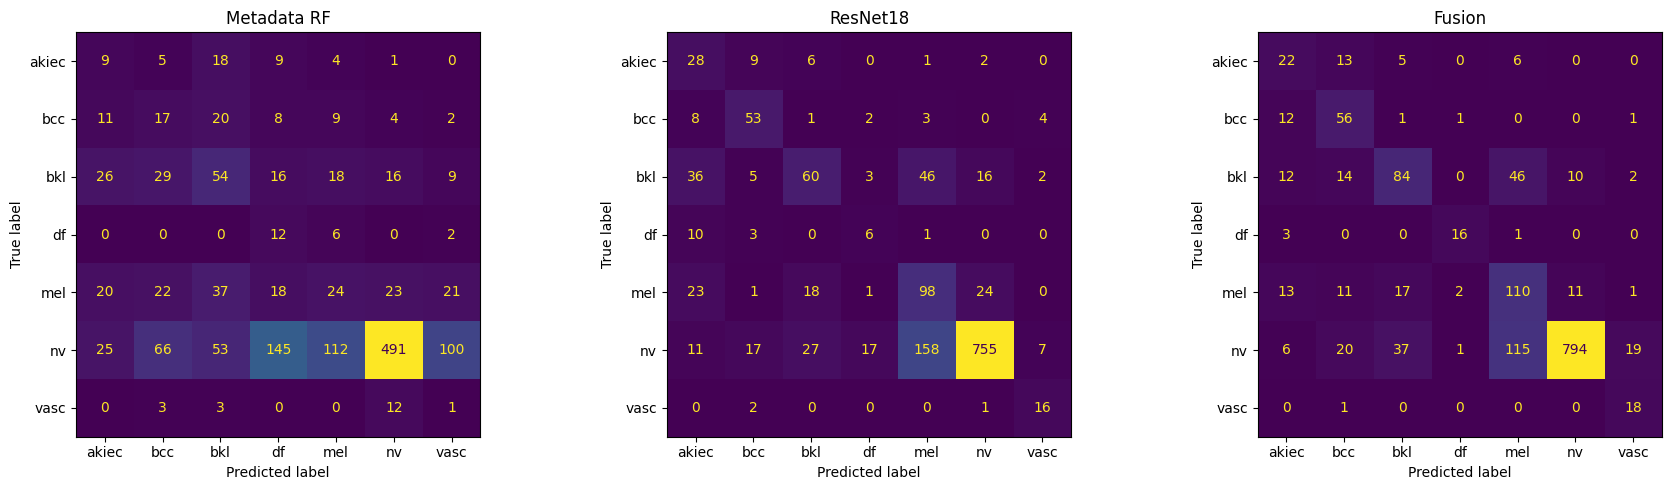

              precision    recall  f1-score   support

       akiec       0.32      0.48      0.39        46
         bcc       0.49      0.79      0.60        71
         bkl       0.58      0.50      0.54       168
          df       0.80      0.80      0.80        20
         mel       0.40      0.67      0.50       165
          nv       0.97      0.80      0.88       992
        vasc       0.44      0.95      0.60        19

    accuracy                           0.74      1481
   macro avg       0.57      0.71      0.61      1481
weighted avg       0.81      0.74      0.76      1481



In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, recall_score
import matplotlib.pyplot as plt

mel = classes.index("mel")
preds = {}

# 1) metadata baseline
te_mask = meta["split"] == "test"
yt = meta.loc[te_mask, "label"].values
preds["Metadata RF"] = rf.predict(meta.loc[te_mask, feat_cols])

# 2) image-only ResNet18 (best epoch)
model.load_state_dict(torch.load(OUT / "resnet18_best.pt"))
_, preds["ResNet18"] = evaluate("test")

# 3) multimodal fusion (best epoch)
fusion.load_state_dict(torch.load(OUT / "fusion_best.pt"))
_, preds["Fusion"] = evaluate2("test")

rows = []
for name, p in preds.items():
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(yt, p),
                 "Macro-F1": f1_score(yt, p, average="macro"),
                 "Melanoma recall": recall_score(yt, p, labels=[mel], average=None)[0]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(yt, p), display_labels=classes).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

print(classification_report(yt, preds["Fusion"], target_names=classes))

# Phase 1, Step 1: New 80/20 split, flattened features and EDA
The Phase 1 sheet asks for an 80/20 split, so the lesion-level split is redone and the images are turned into flat feature tables for the classical methods.

## 1.1 Reload the saved data from Drive
Mounts Drive and loads `images_128.npy` and `meta_processed.csv` from Part B. This is the starting point of Phase 1 after any runtime reset.

In [10]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

OUT = Path("/content/drive/MyDrive/ham10000_processed")
FIG = OUT / "figs"; FIG.mkdir(exist_ok=True)

imgs = np.load(OUT / "images_128.npy")
meta = pd.read_csv(OUT / "meta_processed.csv")
classes = sorted(meta["dx"].unique())
print(imgs.shape, meta.shape, classes)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(10015, 128, 128, 3) (10015, 25) ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


## 1.2 80/20 split by lesion
Stratified split on `lesion_id` into train and test (about 8,000 / 1,995 images), stored in the column `split80`. An `assert` checks that no lesion appears on both sides. The printed table shows the class proportions in each part.

In [11]:
lesions = meta.drop_duplicates("lesion_id")[["lesion_id", "dx"]]
tr_l, te_l = train_test_split(lesions, test_size=0.20, stratify=lesions["dx"], random_state=42)
meta["split80"] = np.where(meta["lesion_id"].isin(tr_l["lesion_id"]), "train", "test")

# sanity check: no lesion appears on both sides
assert set(meta.loc[meta.split80 == "train", "lesion_id"]).isdisjoint(
       set(meta.loc[meta.split80 == "test", "lesion_id"]))

print(meta["split80"].value_counts())
print(meta.groupby("split80")["dx"].value_counts(normalize=True).unstack().round(3))

split80
train    8020
test     1995
Name: count, dtype: int64
dx       akiec    bcc    bkl     df    mel     nv   vasc
split80                                                 
test     0.031  0.050  0.109  0.014  0.109  0.670  0.016
train    0.033  0.052  0.110  0.011  0.112  0.669  0.014


## 1.3 Flattened feature tables
Builds `X_8` (8x8 RGB, 192 features, for the heavy methods), `X_28g` (28x28 grayscale, 784 features, for PCA/LDA/SVD/t-SNE/UMAP) and `X_meta` (age, sex, location). Saves everything to `features_phase1.npz` and `meta_phase1.csv` on Drive, so later steps only load these files.

In [12]:
def shrink(arr, size, gray=False):
    out = []
    for a in arr:
        im = Image.fromarray(a)
        if gray: im = im.convert("L")
        im = im.resize((size, size), Image.BILINEAR)
        out.append(np.asarray(im, dtype=np.float32).ravel() / 255)
    return np.stack(out)

X_8   = shrink(imgs, 8)               # 192 features, for heavy methods
X_28g = shrink(imgs, 28, gray=True)   # 784 features, for PCA/LDA/SVD/t-SNE/UMAP

meta_cols = ["age"] + [c for c in meta.columns if c.startswith(("sex_", "localization_"))]
X_meta = meta[meta_cols].values.astype(np.float32)
y = meta["label"].values
is_train = (meta["split80"] == "train").values
groups = meta["lesion_id"].values

print(X_8.shape, X_28g.shape, X_meta.shape)

np.savez_compressed(OUT / "features_phase1.npz", X_8=X_8, X_28g=X_28g, X_meta=X_meta,
                    y=y, is_train=is_train, groups=groups)
meta.to_csv(OUT / "meta_phase1.csv", index=False)

(10015, 192) (10015, 784) (10015, 19)


## 1.4 Exploratory data analysis (EDA) figures
Missing values, class distribution (about 67% nevi), images per lesion (1,956 of 7,470 lesions have more than one image, which is why the split is by lesion), age and sex by diagnosis, lesion location by diagnosis, and sample images per class. Figures saved as `eda_*.png`. These support the "difficult, noisy dataset" description in the report.
*Note: reads the raw metadata from `/content/data`; if the runtime was reset, change `raw_path` to the Drive path.*

Missing values:
 lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64

Class counts:
 dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


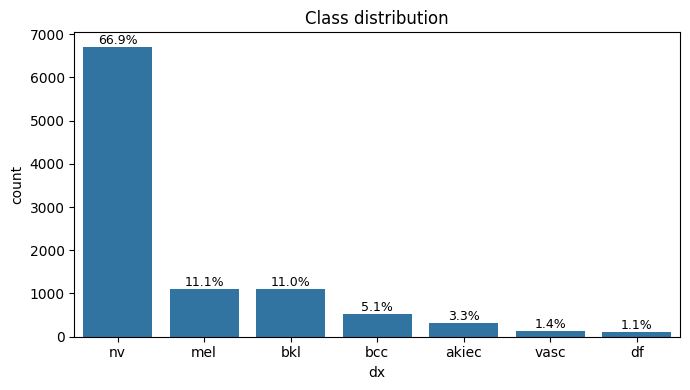


Images per lesion:
 1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64
Lesions with more than one image: 1956 of 7470


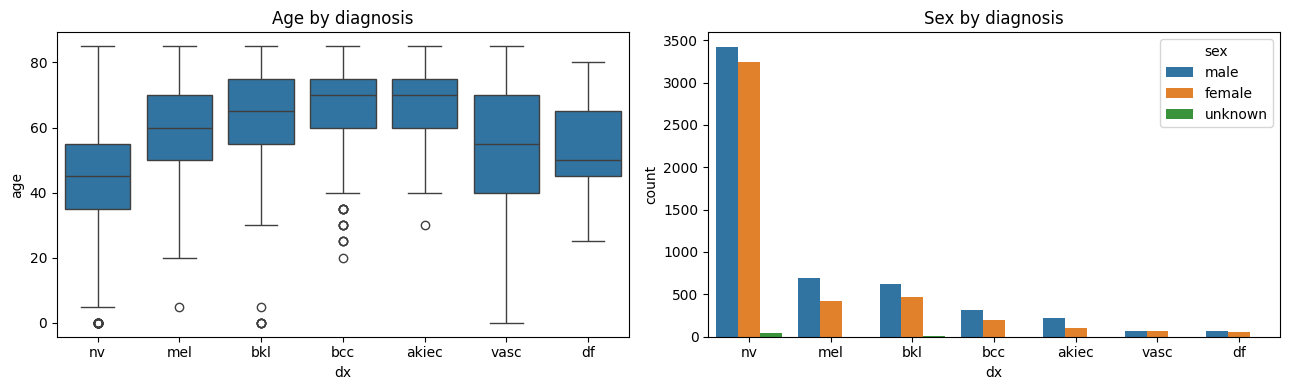

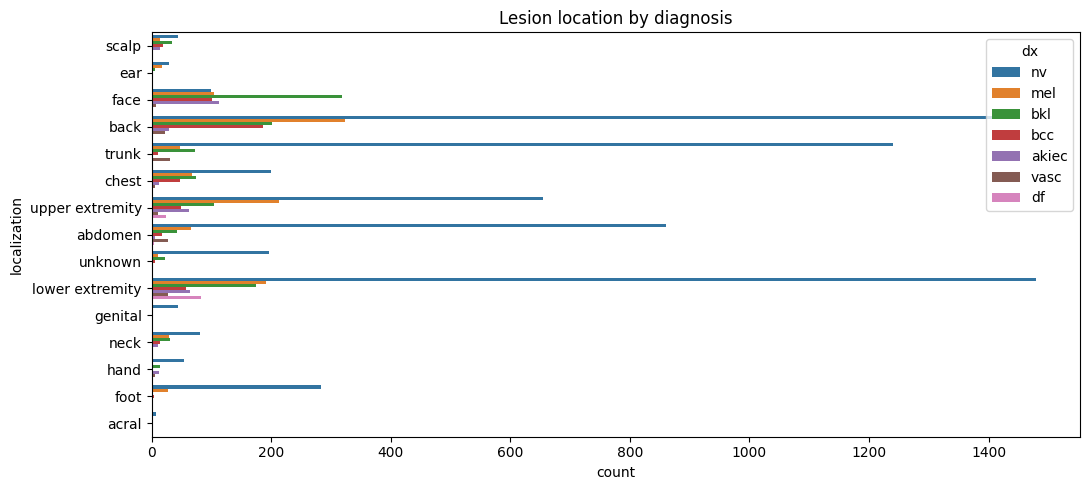

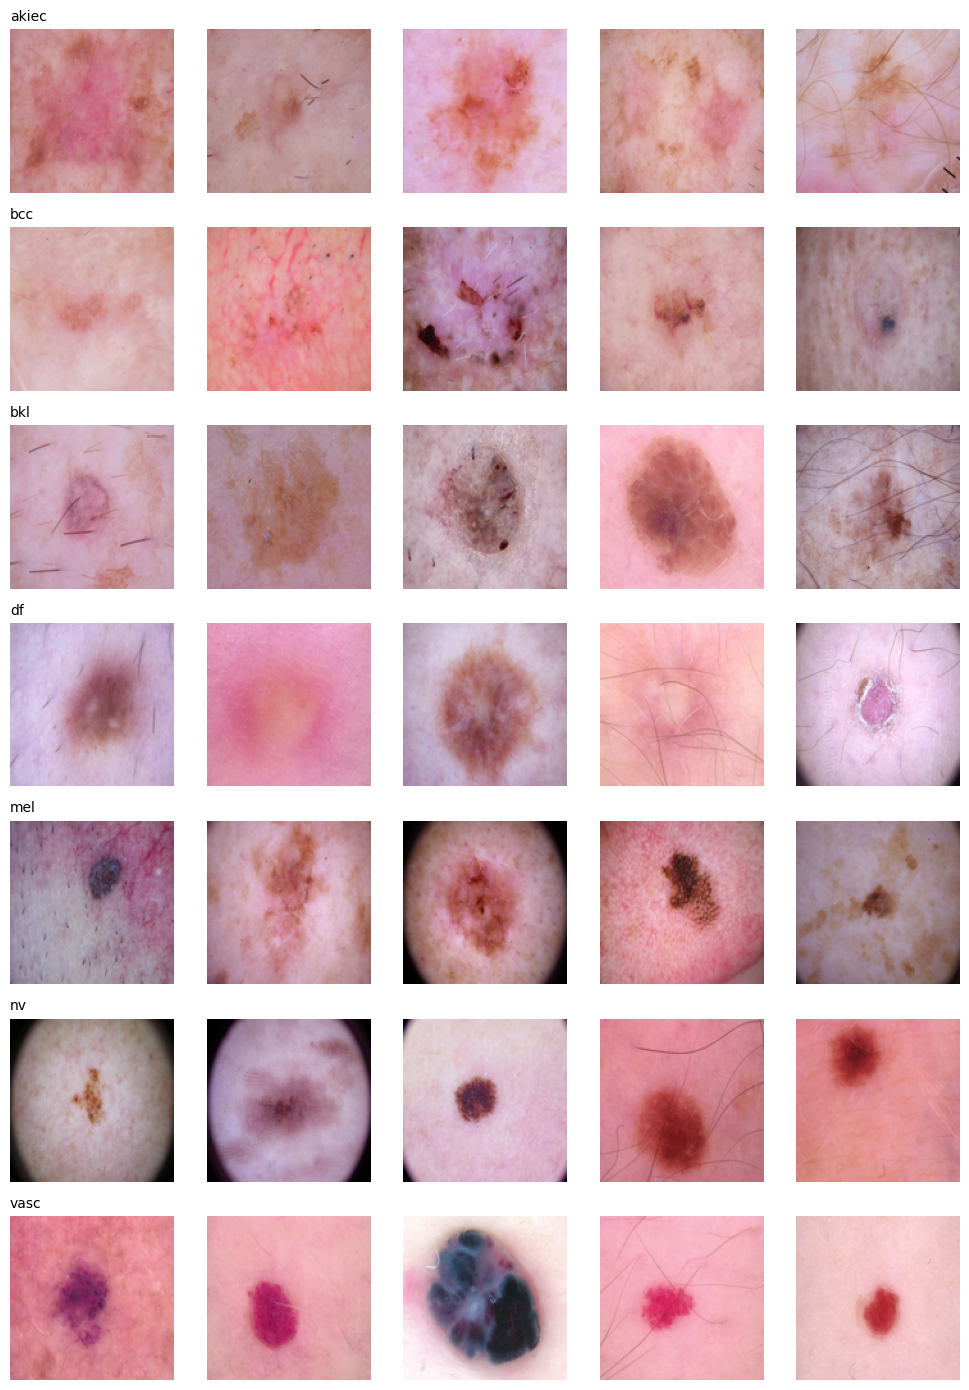

In [13]:
raw_path = Path("/content/data/HAM10000_metadata.csv")   # exists if the session wasn't reset
raw = pd.read_csv(raw_path)

print("Missing values:\n", raw.isna().sum())
print("\nClass counts:\n", raw["dx"].value_counts())

# 1. class distribution
fig, ax = plt.subplots(figsize=(7, 4))
order = raw["dx"].value_counts().index
sns.countplot(data=raw, x="dx", order=order, ax=ax)
for p in ax.patches:
    ax.annotate(f"{100*p.get_height()/len(raw):.1f}%", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Class distribution"); plt.tight_layout(); plt.savefig(FIG/"eda_class_dist.png", dpi=200); plt.show()

# 2. images per lesion
per_lesion = raw.groupby("lesion_id").size()
print("\nImages per lesion:\n", per_lesion.value_counts().sort_index())
print("Lesions with more than one image:", (per_lesion > 1).sum(), "of", len(per_lesion))

# 3. age and sex by diagnosis
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=raw, x="dx", y="age", order=order, ax=axes[0]); axes[0].set_title("Age by diagnosis")
sns.countplot(data=raw, x="dx", hue="sex", order=order, ax=axes[1]); axes[1].set_title("Sex by diagnosis")
plt.tight_layout(); plt.savefig(FIG/"eda_age_sex.png", dpi=200); plt.show()

# 4. body location by diagnosis
plt.figure(figsize=(11, 5))
sns.countplot(data=raw, y="localization", hue="dx", hue_order=order)
plt.title("Lesion location by diagnosis"); plt.tight_layout()
plt.savefig(FIG/"eda_location.png", dpi=200); plt.show()

# 5. sample images per class
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2*len(classes)))
rng = np.random.default_rng(0)
for r, c in enumerate(classes):
    ids = rng.choice(np.where(meta["dx"] == c)[0], 5, replace=False)
    for k, i in enumerate(ids):
        axes[r, k].imshow(imgs[i]); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG/"eda_samples.png", dpi=200); plt.show()

# Phase 1, Step 2: Linear reduction (PCA, LDA, SVD) and clustering

## 2.1 Load features and scale (train statistics only)
Loads `features_phase1.npz`, standardises the 784 grayscale features with a scaler fitted on the training rows, and defines the plotting helper `scatter2d` used by Steps 2 and 3.

In [14]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, f1_score, adjusted_rand_score,
                             normalized_mutual_info_score, silhouette_score)

OUT = Path("/content/drive/MyDrive/ham10000_processed"); FIG = OUT / "figs"
d = np.load(OUT / "features_phase1.npz", allow_pickle=True)
X_raw, y, is_train = d["X_28g"], d["y"], d["is_train"]
classes = sorted(pd.read_csv(OUT / "meta_phase1.csv")["dx"].unique())

sc = StandardScaler().fit(X_raw[is_train])
Xs = sc.transform(X_raw)
Xtr, Xte, ytr, yte = Xs[is_train], Xs[~is_train], y[is_train], y[~is_train]
print(Xtr.shape, Xte.shape)

rng = np.random.default_rng(0)
sub = rng.choice(len(Xtr), 3000, replace=False)   # subsample for plots only

def scatter2d(Z, labels, title, ax):
    for k in np.unique(labels):
        m = labels == k
        ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=.6, label=classes[k] if len(np.unique(labels)) == 7 else k)

(8020, 784) (1995, 784)


## 2.2 PCA
Fits PCA on the training set. Prints how many components keep 90% and 95% of the variance (our run: **15** and **33** of 784). Figure: cumulative variance, a "before" plot (two raw pixels) and an "after" plot (PC1 vs PC2). Saved as `pca.png`. The classes overlap heavily after PCA.

Components for 90% variance: 15 | for 95%: 33


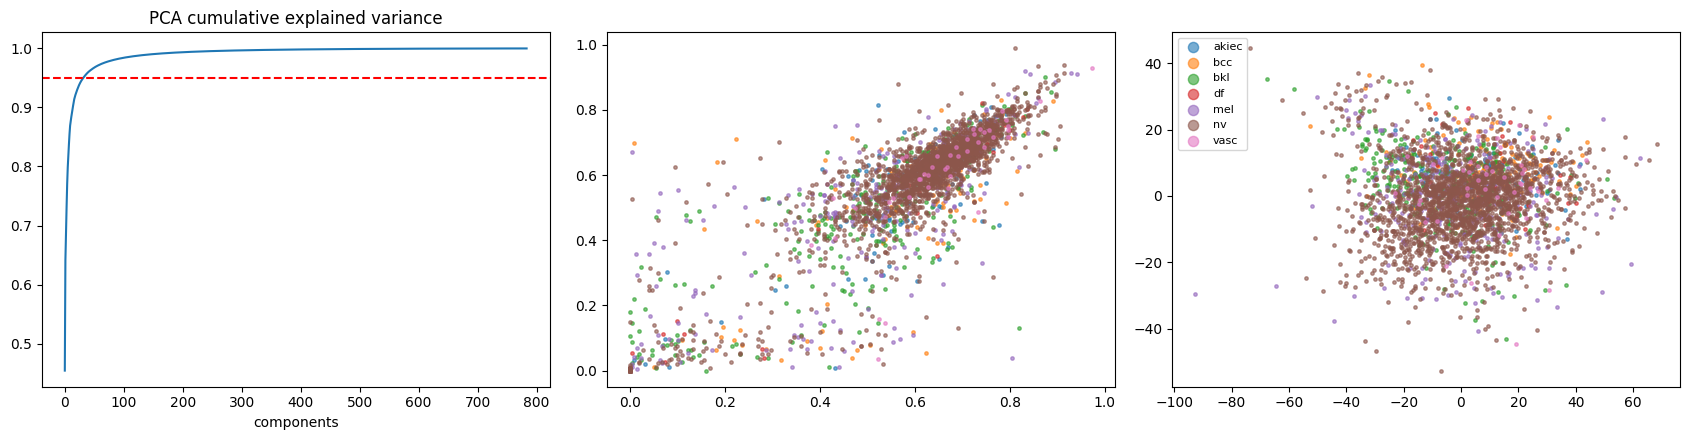

In [15]:
pca = PCA().fit(Xtr)
cum = np.cumsum(pca.explained_variance_ratio_)
n90, n95 = np.searchsorted(cum, .90) + 1, np.searchsorted(cum, .95) + 1
print("Components for 90% variance:", n90, "| for 95%:", n95)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(cum); ax[0].axhline(.95, ls="--", c="r"); ax[0].set_title("PCA cumulative explained variance")
ax[0].set_xlabel("components")

# BEFORE: two raw pixels with the highest variance
top2 = np.argsort(X_raw[is_train].var(0))[-2:]
scatter2d(X_raw[is_train][sub][:, top2], ytr[sub], "Before reduction (2 raw pixels)", ax[1])

# AFTER: first two principal components
Z = pca.transform(Xtr)[:, :2]
scatter2d(Z[sub], ytr[sub], "After PCA (PC1 vs PC2)", ax[2])
ax[2].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "pca.png", dpi=200); plt.show()

## 2.3 LDA and SVD
LDA (supervised, at most 6 components for 7 classes) and truncated SVD (50 components). 2-D plots saved as `lda_svd.png`.

SVD variance explained by 50 components: 0.968


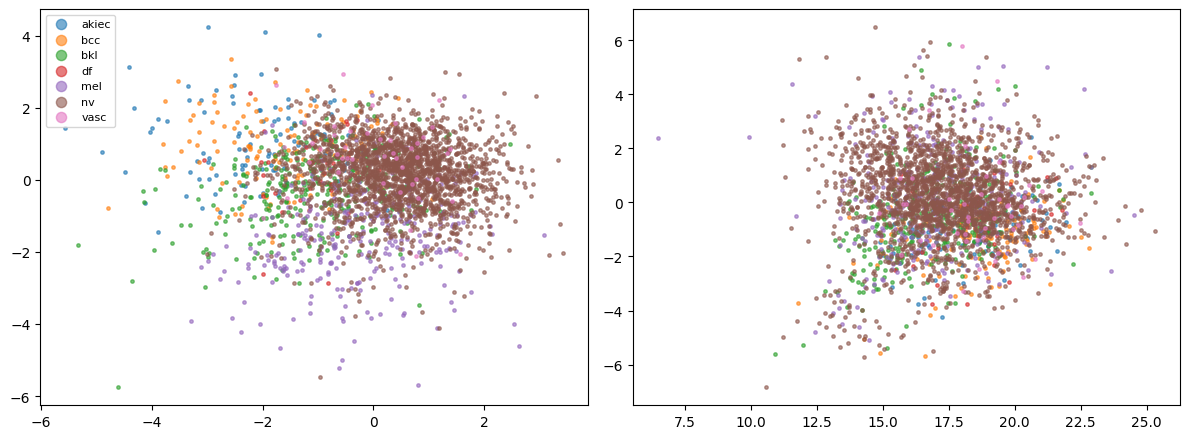

In [16]:
lda = LDA(solver="svd").fit(Xtr, ytr)          # at most 6 components for 7 classes
Z_lda_tr, Z_lda_te = lda.transform(Xtr), lda.transform(Xte)

svd = TruncatedSVD(n_components=50, random_state=42).fit(X_raw[is_train])   # SVD works on uncentered data
Z_svd_tr, Z_svd_te = svd.transform(X_raw[is_train]), svd.transform(X_raw[~is_train])
print("SVD variance explained by 50 components:", svd.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
scatter2d(Z_lda_tr[sub], ytr[sub], "After LDA (LD1 vs LD2)", ax[0]); ax[0].legend(markerscale=3, fontsize=8)
scatter2d(Z_svd_tr[sub], ytr[sub], "After SVD (comp 1 vs 2)", ax[1])
plt.tight_layout(); plt.savefig(FIG / "lda_svd.png", dpi=200); plt.show()

## 2.4 Compare the representations with one classifier
Logistic regression on raw pixels, PCA-50, LDA-6 and SVD-50, with train and test accuracy and macro-F1. Result table saved as `res_linear.csv`. All four reach only about **0.21 to 0.24 test macro-F1**: raw pixels and LDA overfit, PCA and SVD underfit. The `ConvergenceWarning` is harmless (use a larger `max_iter` to silence it).

In [17]:
pca50 = PCA(50, random_state=42).fit(Xtr)
reps = {
    "Raw (784 px)": (Xtr, Xte),
    "PCA (50)":     (pca50.transform(Xtr), pca50.transform(Xte)),
    "LDA (6)":      (Z_lda_tr, Z_lda_te),
    "SVD (50)":     (Z_svd_tr, Z_svd_te),
}
rows = []
for name, (A, B) in reps.items():
    clf = LogisticRegression(max_iter=500, class_weight="balanced").fit(A, ytr)
    p_tr, p_te = clf.predict(A), clf.predict(B)
    rows.append({"Representation": name,
                 "Train acc": accuracy_score(ytr, p_tr), "Test acc": accuracy_score(yte, p_te),
                 "Train macro-F1": f1_score(ytr, p_tr, average="macro"),
                 "Test macro-F1": f1_score(yte, p_te, average="macro")})
res_linear = pd.DataFrame(rows).round(3)
print(res_linear.to_string(index=False))
res_linear.to_csv(OUT / "res_linear.csv", index=False)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Representation  Train acc  Test acc  Train macro-F1  Test macro-F1
  Raw (784 px)      0.614     0.427           0.535          0.222
      PCA (50)      0.376     0.368           0.265          0.241
       LDA (6)      0.595     0.422           0.465          0.206
      SVD (50)      0.372     0.354           0.262          0.238


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 2.5 K-Means clustering (k = 7) in PCA space
Compares the clusters with the true diagnoses using ARI, NMI and silhouette. Our run: ARI 0.006, NMI 0.038, silhouette 0.135, so the clusters do not match the diagnoses. Figure saved as `kmeans.png`. This is the clustering part of the "visualization before/after reduction and clustering" item.

ARI: 0.006 | NMI: 0.038 | Silhouette: 0.135


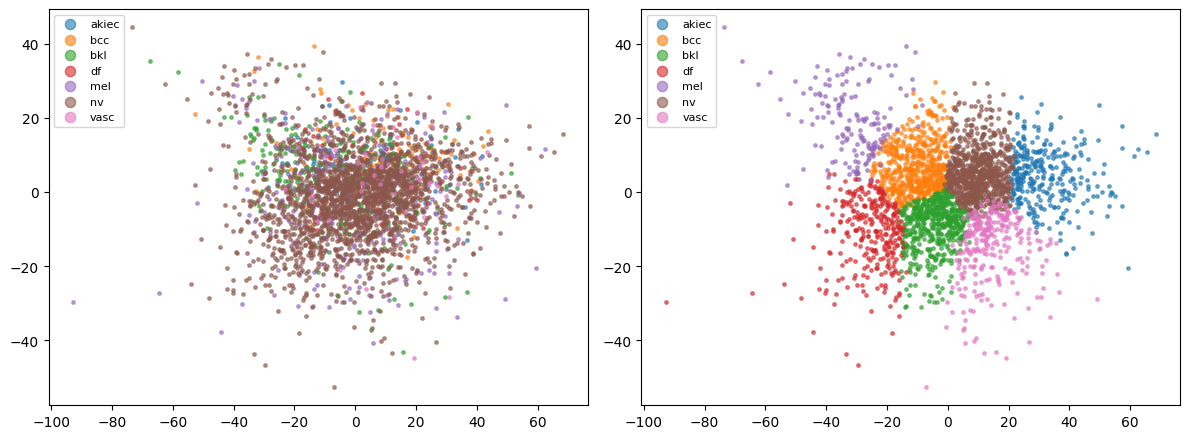

In [18]:
Ztr50 = pca50.transform(Xtr)
km = KMeans(n_clusters=7, n_init=10, random_state=42).fit(Ztr50)
print("ARI:", round(adjusted_rand_score(ytr, km.labels_), 3),
      "| NMI:", round(normalized_mutual_info_score(ytr, km.labels_), 3),
      "| Silhouette:", round(silhouette_score(Ztr50[sub], km.labels_[sub]), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
Z2 = Ztr50[:, :2]
scatter2d(Z2[sub], ytr[sub], "True classes (PCA space)", ax[0]); ax[0].legend(markerscale=3, fontsize=8)
scatter2d(Z2[sub], km.labels_[sub], "K-Means clusters (k=7)", ax[1]); ax[1].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "kmeans.png", dpi=200); plt.show()

# Phase 1, Step 3: Non-linear reduction
Kernel PCA, SNE, t-SNE, UMAP, metric and non-metric MDS, Isomap and LLE, all computed on the 50-D PCA space.

## 3.1 Setup
Installs UMAP and prepares the inputs. The heavy methods are **fitted on a 3,000-image training subsample** and plotted on 1,500 points (state this subsampling in the report).

In [19]:
!pip -q install umap-learn

import umap
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import KernelPCA
from sklearn.manifold import TSNE, MDS, Isomap, LocallyLinearEmbedding, trustworthiness

# all methods work on the 50-D PCA space (fit on train only)
Ztr50, Zte50 = pca50.transform(Xtr), pca50.transform(Xte)

rng = np.random.default_rng(1)
fit_idx = rng.choice(len(Ztr50), 3000, replace=False)   # subsample used to FIT the heavy methods
vis = fit_idx[:1500]                                     # points shown in plots / used by t-SNE, SNE, MDS
Zfit, Zvis, yvis = Ztr50[fit_idx], Ztr50[vis], ytr[vis]
gam = 1.0 / Ztr50.var(0).sum()

## 3.2 Methods that can embed new data: Kernel PCA, Isomap, LLE, UMAP
Each is fitted in 2-D (for the plot) and 10-D (for a logistic-regression classifier scored on the test set). Also computes **trustworthiness** (0 to 1), which measures how well each 2-D map keeps local neighbourhoods. Results are collected in `res_nl`; the printed table appears after 3.3.

In [20]:
makers = {
    "Kernel PCA (RBF)": lambda d: KernelPCA(d, kernel="rbf", gamma=gam),
    "Isomap":           lambda d: Isomap(n_neighbors=15, n_components=d),
    "LLE":              lambda d: LocallyLinearEmbedding(n_neighbors=15, n_components=d, random_state=42),
    "UMAP":             lambda d: umap.UMAP(n_components=d, n_neighbors=15, random_state=42),
}
emb2d, rows = {}, []
for name, mk in makers.items():
    r2 = mk(2).fit(Zfit)                       # 2-D version, for the plot
    emb2d[name] = r2.transform(Zvis)
    r10 = mk(10).fit(Zfit)                     # 10-D version, for classification
    Atr, Ate = r10.transform(Ztr50), r10.transform(Zte50)
    clf = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Atr, ytr)
    rows.append({"Method": name,
                 "Trustworthiness": trustworthiness(Zvis, emb2d[name], n_neighbors=10),
                 "Train macro-F1": f1_score(ytr, clf.predict(Atr), average="macro"),
                 "Test macro-F1": f1_score(yte, clf.predict(Ate), average="macro"),
                 "Test acc": accuracy_score(yte, clf.predict(Ate))})
    print(name, "done")
res_nl = pd.DataFrame(rows)

Kernel PCA (RBF) done
Isomap done
LLE done


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done


## 3.3 Methods with no transform step: SNE, t-SNE, metric and non-metric MDS
These cannot embed new points, so they are used for visualisation and trustworthiness only. scikit-learn has no plain SNE, so `cond_p` and `sne` implement vanilla SNE (Gaussian affinities, asymmetric KL divergence). Prints the full results table and saves it as `res_nonlinear.csv`. In this first run non-metric MDS and LLE gave poor results; they are repaired in 3.5.

In [21]:
def cond_p(X, perplexity=30, iters=60):
    D = squareform(pdist(X, "sqeuclidean")); D = D / np.median(D)
    n = len(X); beta = np.ones(n); lo = np.zeros(n); hi = np.full(n, np.inf)
    target = np.log(perplexity)
    for _ in range(iters):
        P = np.exp(-D * beta[:, None]); np.fill_diagonal(P, 0)
        P /= P.sum(1, keepdims=True) + 1e-12
        H = -(P * np.log(P + 1e-12)).sum(1)
        high = H > target
        lo = np.where(high, beta, lo); hi = np.where(high, hi, beta)
        beta = np.where(high, np.where(np.isinf(hi), beta * 2, (beta + hi) / 2), (beta + lo) / 2)
    return P

def sne(X, perplexity=30, n_iter=500, lr=0.2, seed=0):
    """Vanilla SNE (Hinton & Roweis, 2002): Gaussian affinities in both spaces, asymmetric KL."""
    P = cond_p(X, perplexity)
    r = np.random.default_rng(seed)
    Y = r.normal(0, 1e-2, (len(X), 2)); V = np.zeros_like(Y)
    for it in range(n_iter):
        d = squareform(pdist(Y, "sqeuclidean"))
        Q = np.exp(-d); np.fill_diagonal(Q, 0); Q /= Q.sum(1, keepdims=True) + 1e-12
        M = P - Q + P.T - Q.T
        grad = 2 * (M.sum(1)[:, None] * Y - M @ Y)
        V = (0.5 if it < 100 else 0.8) * V - lr * grad
        Y = Y + V
    return Y

emb2d["t-SNE"]  = TSNE(2, perplexity=30, init="pca", random_state=42).fit_transform(Zvis)
emb2d["SNE"]    = sne(Zvis)
emb2d["Metric MDS"]     = MDS(2, metric=True,  n_init=1, max_iter=100, random_state=42).fit_transform(Zvis)
emb2d["Non-metric MDS"] = MDS(2, metric=False, n_init=1, max_iter=100, random_state=42).fit_transform(Zvis)

extra = pd.DataFrame([{"Method": n, "Trustworthiness": trustworthiness(Zvis, emb2d[n], n_neighbors=10)}
                      for n in ["t-SNE", "SNE", "Metric MDS", "Non-metric MDS"]])
res_nl = pd.concat([res_nl, extra], ignore_index=True).round(3)
print(res_nl.to_string(index=False))
res_nl.to_csv(OUT / "res_nonlinear.csv", index=False)

          Method  Trustworthiness  Train macro-F1  Test macro-F1  Test acc
Kernel PCA (RBF)            0.807           0.220          0.224     0.323
          Isomap            0.896           0.212          0.208     0.293
             LLE            0.780           0.197          0.209     0.354
            UMAP            0.906           0.208          0.196     0.264
           t-SNE            0.951             NaN            NaN       NaN
             SNE            0.900             NaN            NaN       NaN
      Metric MDS            0.853             NaN            NaN       NaN
  Non-metric MDS            0.498             NaN            NaN       NaN


## 3.4 Figure: all eight methods
Draws the eight 2-D maps in one figure (`nonlinear_all.png`). **Run this cell again after 3.5** to get the corrected non-metric MDS and LLE panels. In every panel the seven classes overlap.

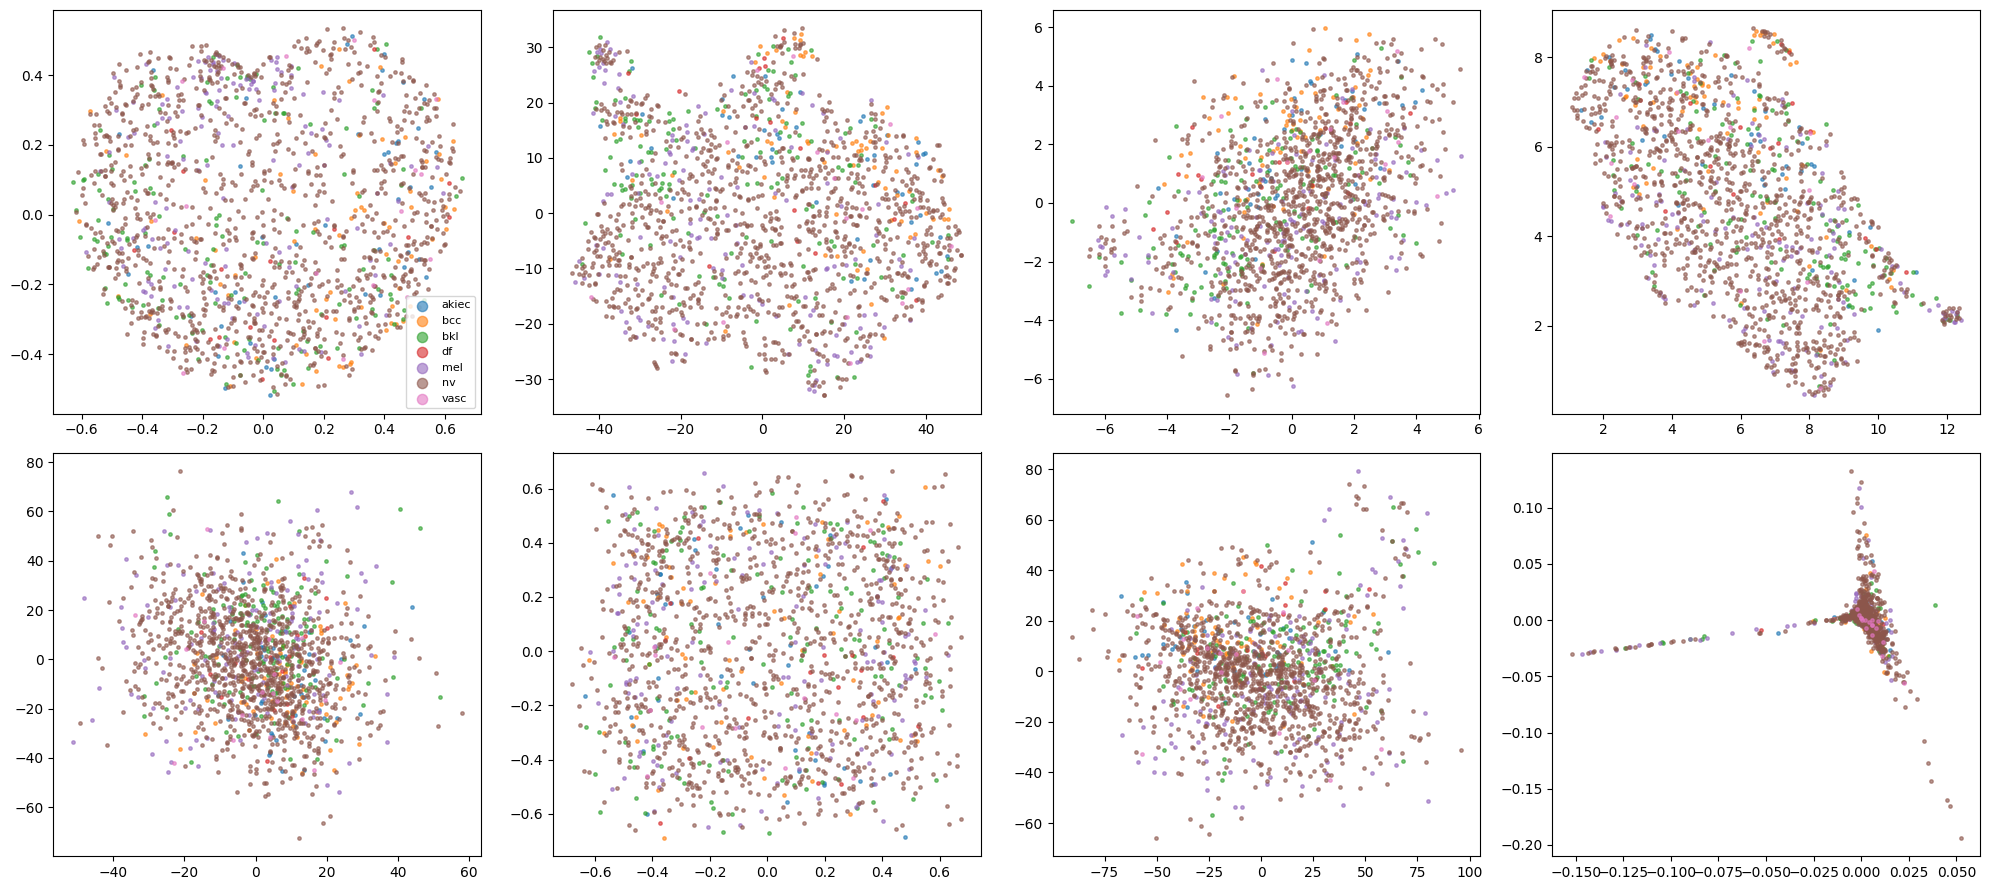

In [22]:
order = ["Kernel PCA (RBF)", "t-SNE", "SNE", "UMAP", "Metric MDS", "Non-metric MDS", "Isomap", "LLE"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), order):
    scatter2d(emb2d[name], yvis, name, ax)
axes[0, 0].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "nonlinear_all.png", dpi=200); plt.show()

## 3.5 Fix for the two failed runs
- **Non-metric MDS:** restarted from the metric-MDS solution with 300 iterations (trustworthiness 0.498 to 0.854).
- **LLE:** re-run with 30 neighbours and stronger regularisation (it had collapsed onto a line; trustworthiness 0.811).

Updates `res_nl` and re-saves `res_nonlinear.csv`. Only the transform-capable methods (Kernel PCA, Isomap, LLE, UMAP) get classifier scores, all about 0.20 to 0.22 macro-F1.

In [23]:
# --- Non-metric MDS: start from the metric MDS solution, more iterations
emb2d["Non-metric MDS"] = MDS(2, metric=False, n_init=1, max_iter=300, random_state=42)\
                            .fit_transform(Zvis, init=emb2d["Metric MDS"])
res_nl.loc[res_nl.Method == "Non-metric MDS", "Trustworthiness"] = \
    trustworthiness(Zvis, emb2d["Non-metric MDS"], n_neighbors=10)

# --- LLE: more neighbours + stronger regularization
mk = lambda d: LocallyLinearEmbedding(n_neighbors=30, n_components=d, reg=1e-1, random_state=42)
emb2d["LLE"] = mk(2).fit(Zfit).transform(Zvis)
r10 = mk(10).fit(Zfit)
Atr, Ate = r10.transform(Ztr50), r10.transform(Zte50)
clf = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Atr, ytr)
res_nl.loc[res_nl.Method == "LLE", ["Trustworthiness", "Train macro-F1", "Test macro-F1", "Test acc"]] = [
    trustworthiness(Zvis, emb2d["LLE"], n_neighbors=10),
    f1_score(ytr, clf.predict(Atr), average="macro"),
    f1_score(yte, clf.predict(Ate), average="macro"),
    accuracy_score(yte, clf.predict(Ate))]

res_nl = res_nl.round(3)
print(res_nl.to_string(index=False))
res_nl.to_csv(OUT / "res_nonlinear.csv", index=False)

          Method  Trustworthiness  Train macro-F1  Test macro-F1  Test acc
Kernel PCA (RBF)            0.807           0.220          0.224     0.323
          Isomap            0.896           0.212          0.208     0.293
             LLE            0.811           0.202          0.202     0.304
            UMAP            0.906           0.208          0.196     0.264
           t-SNE            0.951             NaN            NaN       NaN
             SNE            0.900             NaN            NaN       NaN
      Metric MDS            0.853             NaN            NaN       NaN
  Non-metric MDS            0.854             NaN            NaN       NaN


# Phase 1, Step 4: Handcrafted features and filter selection
Pixel features were weak, so a small table of interpretable features is built and used for feature selection.

## 4.1 Build the 47-feature table
**28 image features** (per-channel RGB mean, std and skew; HSV mean and std; centre-region and border-region colour and their difference; gradient and Laplacian statistics; grey-level entropy) plus **19 metadata features** (age, sex, location). Scaled with train statistics only; saved as `features_handcrafted.npz`. Takes about 2 minutes.

In [24]:
from matplotlib.colors import rgb_to_hsv
from scipy.stats import skew
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif, f_classif

imgs = np.load(OUT / "images_128.npy", mmap_mode="r")
meta = pd.read_csv(OUT / "meta_phase1.csv")
meta_cols = ["age"] + [c for c in meta.columns if c.startswith(("sex_", "localization_"))]
X_meta = d["X_meta"]

img_names = ([f"{c}_mean" for c in "RGB"] + [f"{c}_std" for c in "RGB"] + [f"{c}_skew" for c in "RGB"]
           + ["H_mean","S_mean","V_mean","H_std","S_std","V_std"]
           + [f"{c}_center" for c in "RGB"] + [f"{c}_border" for c in "RGB"]
           + [f"{c}_center_minus_border" for c in "RGB"]
           + ["grad_mean","grad_std","laplacian_var","gray_entropy"])

def extract(batch):
    f = batch.astype(np.float32) / 255; n = len(f)
    mean, std = f.mean((1, 2)), f.std((1, 2))
    sk = np.nan_to_num(skew(f.reshape(n, -1, 3), axis=1))
    hsv = rgb_to_hsv(f); hm, hs = hsv.mean((1, 2)), hsv.std((1, 2))
    cen = f[:, 32:96, 32:96].mean((1, 2))
    bor = (f.sum((1, 2)) - f[:, 32:96, 32:96].sum((1, 2))) / (128 * 128 - 64 * 64)
    g = f.mean(3)
    gx = np.diff(g, axis=2)[:, :-1, :]; gy = np.diff(g, axis=1)[:, :, :-1]
    grad = np.sqrt(gx ** 2 + gy ** 2)
    lap = 4 * g[:, 1:-1, 1:-1] - g[:, :-2, 1:-1] - g[:, 2:, 1:-1] - g[:, 1:-1, :-2] - g[:, 1:-1, 2:]
    ent = np.zeros(n, np.float32)
    for i in range(n):
        p = np.bincount((g[i] * 31).astype(int).ravel(), minlength=32) / g[i].size
        p = p[p > 0]; ent[i] = -(p * np.log2(p)).sum()
    return np.column_stack([mean, std, sk, hm, hs, cen, bor, cen - bor,
                            grad.mean((1, 2)), grad.std((1, 2)), lap.var((1, 2)), ent]).astype(np.float32)

X_img = np.vstack([extract(np.asarray(imgs[i:i+500])) for i in range(0, len(imgs), 500)])
feat_names = img_names + meta_cols
X_feat = np.hstack([X_img, X_meta])
print(X_feat.shape, "NaNs:", np.isnan(X_feat).sum())

# scale with TRAIN statistics only
sc_f = StandardScaler().fit(X_feat[is_train])
Xf = sc_f.transform(X_feat)
Xtr_f, Xte_f = Xf[is_train], Xf[~is_train]
groups_tr = d["groups"][is_train]

np.savez_compressed(OUT / "features_handcrafted.npz", X=X_feat, names=np.array(feat_names))

(10015, 47) NaNs: 0


## 4.2 Baseline with all 47 features and the reusable evaluator
`evaluate_subset(cols, name)` trains a Random Forest on any feature subset and reports train and test macro-F1 and accuracy. Every selection method below is scored with it. Reference row (our run): all 47 features, test macro-F1 **0.457**, accuracy 0.749, train macro-F1 0.974 (strong overfitting). Results accumulate in `sel_results`.

In [25]:
def evaluate_subset(cols, name):
    rf = RandomForestClassifier(300, class_weight="balanced_subsample", min_samples_leaf=3,
                                n_jobs=-1, random_state=42).fit(Xtr_f[:, cols], ytr)
    ptr, pte = rf.predict(Xtr_f[:, cols]), rf.predict(Xte_f[:, cols])
    return {"Method": name, "# features": len(cols),
            "Train macro-F1": f1_score(ytr, ptr, average="macro"),
            "Test macro-F1": f1_score(yte, pte, average="macro"),
            "Test acc": accuracy_score(yte, pte)}

all_cols = list(range(len(feat_names)))
sel_results = [evaluate_subset(all_cols, "All features")]
print(pd.DataFrame(sel_results).round(3).to_string(index=False))

      Method  # features  Train macro-F1  Test macro-F1  Test acc
All features          47           0.974          0.457     0.749


## 4.3 Filter methods: mutual information and ANOVA F-test
Ranks the features by each score (training data only) and evaluates the top 5, 10, 15, 20 and 30. Prints the top-10 features and saves `filter_scores.png` and `res_selection.csv`. **Sheet item: filter methods.**

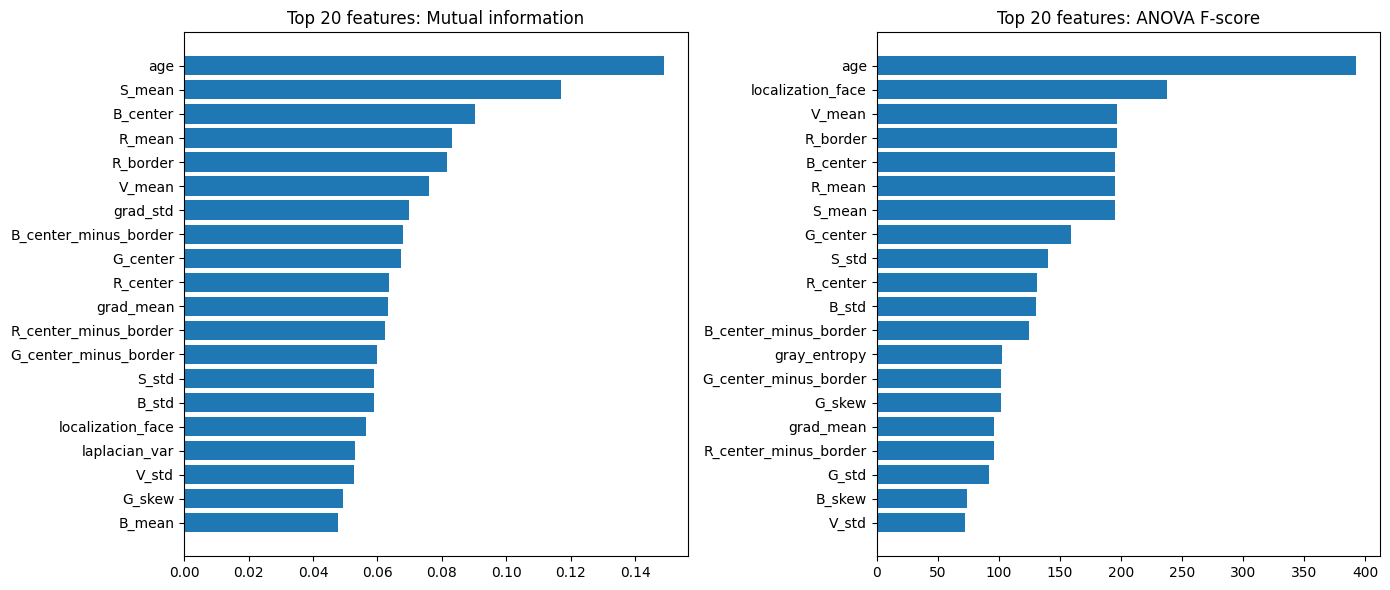

Top 10 by MI : ['age', 'S_mean', 'B_center', 'R_mean', 'R_border', 'V_mean', 'grad_std', 'B_center_minus_border', 'G_center', 'R_center']
Top 10 by F  : ['age', 'localization_face', 'V_mean', 'R_border', 'B_center', 'R_mean', 'S_mean', 'G_center', 'S_std', 'R_center']
                Method  # features  Train macro-F1  Test macro-F1  Test acc
          All features          47           0.974          0.457     0.749
      Filter: MI top-5           5           0.893          0.316     0.675
 Filter: ANOVA-F top-5           5           0.860          0.283     0.648
     Filter: MI top-10          10           0.936          0.348     0.690
Filter: ANOVA-F top-10          10           0.936          0.371     0.709
     Filter: MI top-15          15           0.960          0.414     0.724
Filter: ANOVA-F top-15          15           0.957          0.426     0.735
     Filter: MI top-20          20           0.966          0.423     0.737
Filter: ANOVA-F top-20          20           0.

In [26]:
mi = mutual_info_classif(Xtr_f, ytr, random_state=42)
fs, _ = f_classif(Xtr_f, ytr)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, sc_, title in zip(ax, [mi, fs], ["Mutual information", "ANOVA F-score"]):
    o = np.argsort(sc_)[::-1][:20]
    a.barh([feat_names[i] for i in o][::-1], sc_[o][::-1]); a.set_title(f"Top 20 features: {title}")
plt.tight_layout(); plt.savefig(FIG / "filter_scores.png", dpi=200); plt.show()

rank_mi, rank_f = np.argsort(mi)[::-1], np.argsort(fs)[::-1]
print("Top 10 by MI :", [feat_names[i] for i in rank_mi[:10]])
print("Top 10 by F  :", [feat_names[i] for i in rank_f[:10]])

for k in [5, 10, 15, 20, 30]:
    sel_results.append(evaluate_subset(list(rank_mi[:k]), f"Filter: MI top-{k}"))
    sel_results.append(evaluate_subset(list(rank_f[:k]),  f"Filter: ANOVA-F top-{k}"))
res_sel = pd.DataFrame(sel_results).round(3)
print(res_sel.to_string(index=False))
res_sel.to_csv(OUT / "res_selection.csv", index=False)

# Phase 1, Step 5: Wrapper, embedded and genetic-algorithm selection

## 5.1 Wrapper methods: forward and backward selection
Sequential feature selection down to 15 features, using logistic regression and lesion-grouped 3-fold cross-validation on a 2,500-image subsample. **Slow (several minutes).** Prints the chosen features and adds both results to `sel_results`. **Sheet item: wrapper methods.**

In [27]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.linear_model import LogisticRegression

r = np.random.default_rng(0)
ws = r.choice(len(Xtr_f), 2500, replace=False)            # subsample keeps it fast
cv = list(GroupKFold(3).split(Xtr_f[ws], ytr[ws], groups_tr[ws]))   # grouped by lesion
lr = LogisticRegression(max_iter=300, class_weight="balanced")

for direction in ["forward", "backward"]:
    sfs = SequentialFeatureSelector(lr, n_features_to_select=15, direction=direction,
                                    scoring="f1_macro", cv=cv, n_jobs=-1).fit(Xtr_f[ws], ytr[ws])
    cols = list(np.where(sfs.get_support())[0])
    print(f"\n{direction}:", [feat_names[i] for i in cols])
    sel_results.append(evaluate_subset(cols, f"Wrapper: {direction} (15)"))
print(pd.DataFrame(sel_results).round(3).tail(2).to_string(index=False))


forward: ['R_mean', 'B_mean', 'G_std', 'B_std', 'B_skew', 'R_center', 'B_center', 'G_center_minus_border', 'grad_mean', 'laplacian_var', 'age', 'localization_abdomen', 'localization_face', 'localization_lower extremity', 'localization_upper extremity']

backward: ['B_std', 'R_skew', 'G_skew', 'S_mean', 'V_std', 'G_border', 'R_center_minus_border', 'G_center_minus_border', 'B_center_minus_border', 'grad_mean', 'laplacian_var', 'age', 'localization_genital', 'localization_lower extremity', 'localization_upper extremity']
                Method  # features  Train macro-F1  Test macro-F1  Test acc
 Wrapper: forward (15)          15           0.957          0.422     0.739
Wrapper: backward (15)          15           0.968          0.440     0.731


## 5.2 Embedded methods: L1, L2, Elastic Net and Random-Forest importance
Logistic regression with each penalty (the regularisation strength is chosen to keep 25 or fewer features; L2 cannot zero out features, so its top-k by coefficient size is used), plus tree-based importance. Prints how many features each C value keeps and saves `embedded.png`. **Sheet item: embedded methods.**

L1  C=0.002: 12 features kept
L1  C=0.005: 26 features kept
L1  C=0.01: 38 features kept
L1  C=0.02: 43 features kept
L1  C=0.05: 45 features kept
L1  C=0.1: 47 features kept
ElasticNet  C=0.002: 26 features kept
ElasticNet  C=0.005: 43 features kept
ElasticNet  C=0.01: 46 features kept
ElasticNet  C=0.02: 46 features kept
ElasticNet  C=0.05: 47 features kept
ElasticNet  C=0.1: 47 features kept


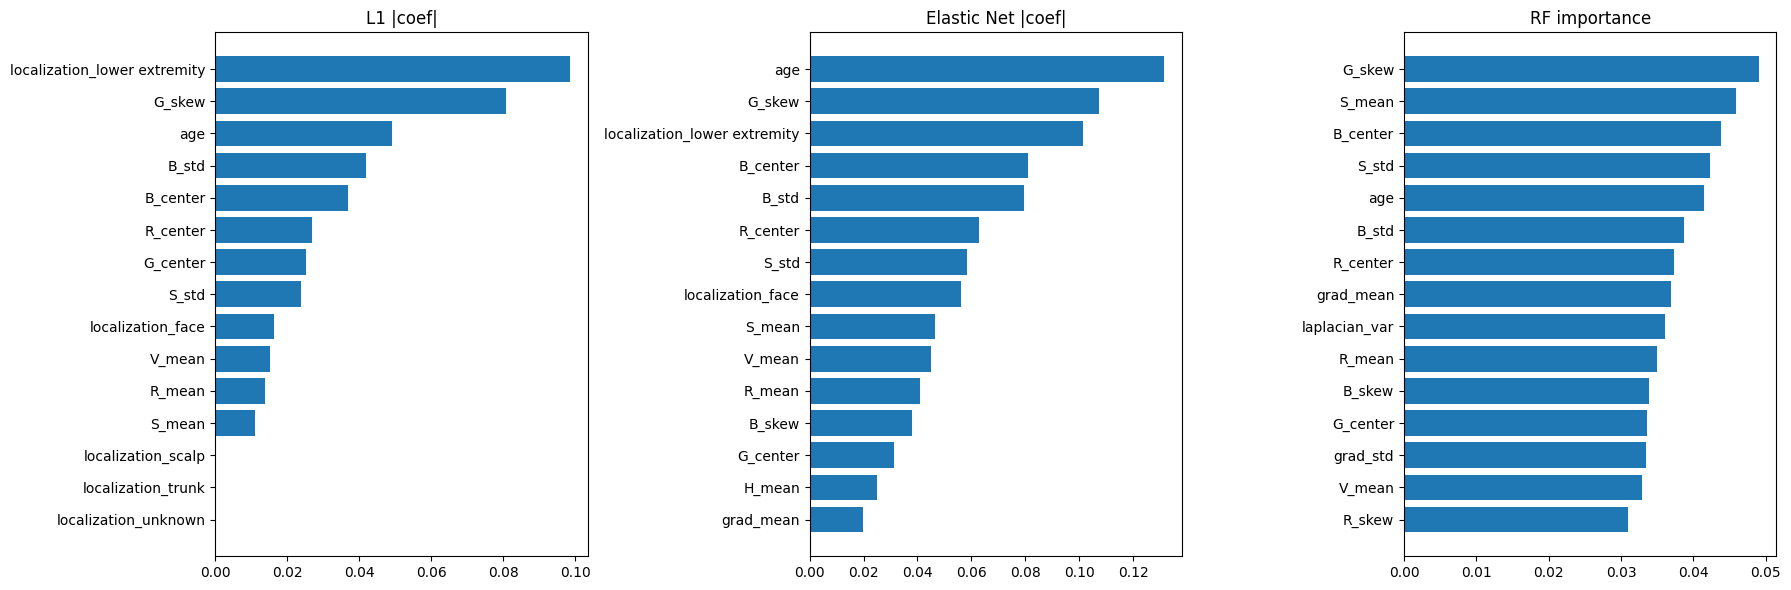

                         Method  # features  Train macro-F1  Test macro-F1  Test acc
         Embedded: L1 (C=0.002)          12           0.941          0.427     0.727
Embedded: Elastic Net (C=0.002)          26           0.969          0.463     0.749
            Embedded: L2 top-12          12           0.970          0.388     0.718
 Embedded: RF importance top-12          12           0.956          0.408     0.736


In [28]:
def make(kind, C):
    kw = dict(solver="saga", C=C, max_iter=300, tol=1e-3, class_weight="balanced", random_state=42)
    if kind == "L1": return LogisticRegression(penalty="l1", **kw)
    if kind == "L2": return LogisticRegression(penalty="l2", **kw)
    return LogisticRegression(penalty="elasticnet", l1_ratio=0.5, **kw)

def sparse_fit(kind, max_feats=25):
    chosen = None
    for C in [0.002, 0.005, 0.01, 0.02, 0.05, 0.1]:
        m = make(kind, C).fit(Xtr_f, ytr)
        nz = np.where(np.abs(m.coef_).max(0) > 1e-6)[0]
        print(f"{kind}  C={C}: {len(nz)} features kept")
        if chosen is None or len(nz) <= max_feats: chosen = (C, m, nz)
    return chosen

C1, m1, nz1 = sparse_fit("L1")
Ce, me, nze = sparse_fit("ElasticNet")
sel_results.append(evaluate_subset(list(nz1), f"Embedded: L1 (C={C1})"))
sel_results.append(evaluate_subset(list(nze), f"Embedded: Elastic Net (C={Ce})"))

# L2 never zeroes coefficients, so rank by mean |coef| and keep the same number as L1
m2 = make("L2", 0.05).fit(Xtr_f, ytr)
k = len(nz1)
top2 = list(np.argsort(np.abs(m2.coef_).mean(0))[::-1][:k])
sel_results.append(evaluate_subset(top2, f"Embedded: L2 top-{k}"))

# tree-based embedded selection
rf_imp = RandomForestClassifier(300, class_weight="balanced_subsample", min_samples_leaf=3,
                                n_jobs=-1, random_state=42).fit(Xtr_f, ytr)
toprf = list(np.argsort(rf_imp.feature_importances_)[::-1][:k])
sel_results.append(evaluate_subset(toprf, f"Embedded: RF importance top-{k}"))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (t_, v) in zip(ax, [("L1 |coef|", np.abs(m1.coef_).mean(0)),
                           ("Elastic Net |coef|", np.abs(me.coef_).mean(0)),
                           ("RF importance", rf_imp.feature_importances_)]):
    o = np.argsort(v)[::-1][:15]
    a.barh([feat_names[i] for i in o][::-1], v[o][::-1]); a.set_title(t_)
plt.tight_layout(); plt.savefig(FIG / "embedded.png", dpi=200); plt.show()
print(pd.DataFrame(sel_results).round(3).tail(4).to_string(index=False))

## 5.3 Genetic algorithm (metaheuristic)
Population 20, 15 generations, tournament selection, uniform crossover, 3% bit-flip mutation, elitism. Fitness = macro-F1 on a lesion-grouped hold-out of the **training** set minus 0.002 per selected feature. **Slow (5 to 10 minutes).** Prints the best and mean fitness per generation and the selected features, and saves `ga_convergence.png`. Our run selected 21 features and the best fitness rose from 0.382 to 0.454. **Sheet item: GA and other metaheuristics.**

gen 1: best 0.3817  mean 0.3412
gen 2: best 0.4086  mean 0.3676
gen 3: best 0.4360  mean 0.3850
gen 4: best 0.4360  mean 0.3975
gen 5: best 0.4360  mean 0.4077
gen 6: best 0.4360  mean 0.4076
gen 7: best 0.4360  mean 0.4095
gen 8: best 0.4360  mean 0.4082
gen 9: best 0.4429  mean 0.4189
gen 10: best 0.4429  mean 0.4138
gen 11: best 0.4429  mean 0.4196
gen 12: best 0.4429  mean 0.4112
gen 13: best 0.4544  mean 0.4192
gen 14: best 0.4544  mean 0.4162
gen 15: best 0.4544  mean 0.4115

GA selected 21 features: ['G_mean', 'R_std', 'G_std', 'B_std', 'R_skew', 'G_skew', 'H_mean', 'V_mean', 'S_std', 'G_center', 'R_center_minus_border', 'grad_std', 'gray_entropy', 'age', 'localization_abdomen', 'localization_back', 'localization_chest', 'localization_ear', 'localization_face', 'localization_lower extremity', 'localization_unknown']


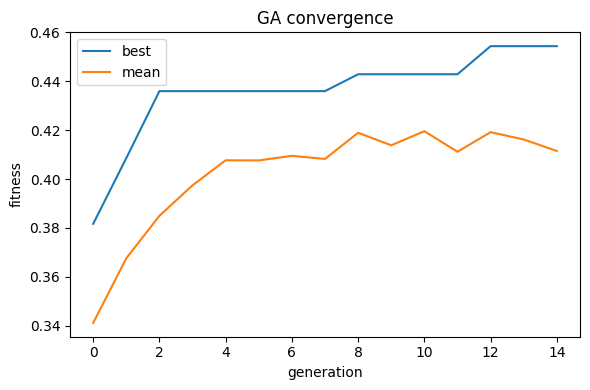

In [29]:
tr_i, va_i = next(GroupShuffleSplit(1, test_size=0.25, random_state=0).split(Xtr_f, ytr, groups_tr))
cache = {}
def fitness(mask, alpha=0.002):
    key = mask.tobytes()
    if key in cache: return cache[key]
    if mask.sum() == 0: return 0.0
    rf = RandomForestClassifier(40, max_depth=8, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=0).fit(Xtr_f[tr_i][:, mask], ytr[tr_i])
    f = f1_score(ytr[va_i], rf.predict(Xtr_f[va_i][:, mask]), average="macro") - alpha * mask.sum()
    cache[key] = f; return f

def run_ga(n_feat, pop_size=20, gens=15, p_mut=0.03, seed=0):
    r = np.random.default_rng(seed)
    pop = r.random((pop_size, n_feat)) < 0.5
    best_hist, mean_hist = [], []
    for g in range(gens):
        fit = np.array([fitness(ind) for ind in pop])
        best_hist.append(fit.max()); mean_hist.append(fit.mean())
        print(f"gen {g+1}: best {fit.max():.4f}  mean {fit.mean():.4f}")
        order = np.argsort(fit)[::-1]
        new = [pop[order[0]].copy(), pop[order[1]].copy()]                 # elitism
        def pick():
            c = r.choice(pop_size, 3, replace=False); return pop[c[np.argmax(fit[c])]]
        while len(new) < pop_size:
            child = np.where(r.random(n_feat) < 0.5, pick(), pick())       # uniform crossover
            child = child ^ (r.random(n_feat) < p_mut)                     # bit-flip mutation
            if not child.any(): child[r.integers(n_feat)] = True
            new.append(child)
        pop = np.array(new)
    fit = np.array([fitness(ind) for ind in pop])
    return pop[np.argmax(fit)], best_hist, mean_hist

best, bh, mh = run_ga(len(feat_names))
ga_cols = list(np.where(best)[0])
print("\nGA selected", len(ga_cols), "features:", [feat_names[i] for i in ga_cols])
sel_results.append(evaluate_subset(ga_cols, f"Metaheuristic: GA ({len(ga_cols)})"))

plt.figure(figsize=(6, 4)); plt.plot(bh, label="best"); plt.plot(mh, label="mean")
plt.xlabel("generation"); plt.ylabel("fitness"); plt.title("GA convergence"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "ga_convergence.png", dpi=200); plt.show()

## 5.4 Comparison of all selection methods
One sorted table (train/test macro-F1, accuracy and the train-test gap) and a plot of feature count against test performance. Saved as `res_selection.csv` and `selection_summary.png`. Main finding: no method clearly beats all 47 features; differences under about 0.03 are noise.

**Note on classifiers:** this comparison scores every feature subset with one fixed, lightly regularised Random Forest (`min_samples_leaf=3`, no depth limit), so the selection methods are compared fairly with each other. The final models in Step 6 use a more regularised Random Forest (`min_samples_leaf=5`, `max_depth=12`). The same GA (21) feature set therefore scores 0.438 here and 0.464 in Step 6: the feature set is identical, only the Random Forest settings differ. Compare numbers only within one table.

                         Method  # features  Train macro-F1  Test macro-F1  Test acc  Gap (train-test F1)
         Filter: ANOVA-F top-30          30           0.972          0.477     0.749                0.495
Embedded: Elastic Net (C=0.002)          26           0.969          0.463     0.749                0.506
                   All features          47           0.974          0.457     0.749                0.517
         Wrapper: backward (15)          15           0.968          0.440     0.731                0.528
         Metaheuristic: GA (21)          21           0.969          0.438     0.753                0.531
         Embedded: L1 (C=0.002)          12           0.941          0.427     0.727                0.514
         Filter: ANOVA-F top-15          15           0.957          0.426     0.735                0.531
         Filter: ANOVA-F top-20          20           0.968          0.424     0.742                0.544
              Filter: MI top-20          20   

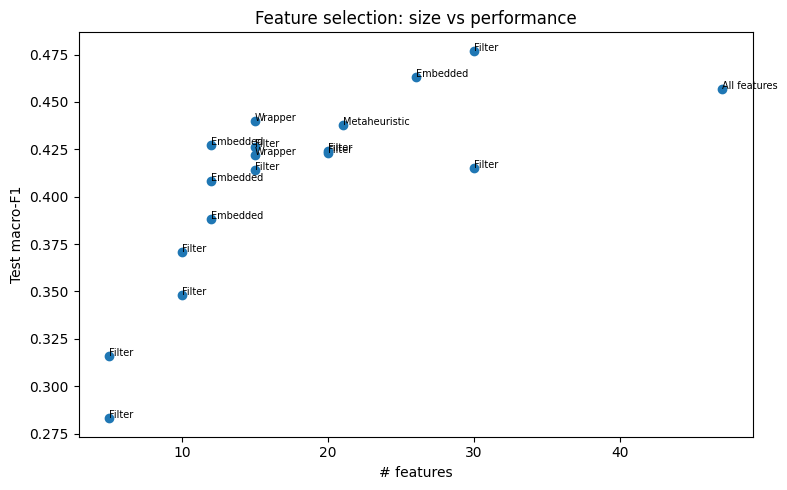

In [30]:
res_sel = pd.DataFrame(sel_results).round(3)
res_sel["Gap (train-test F1)"] = (res_sel["Train macro-F1"] - res_sel["Test macro-F1"]).round(3)
res_sel = res_sel.sort_values("Test macro-F1", ascending=False)
print(res_sel.to_string(index=False))
res_sel.to_csv(OUT / "res_selection.csv", index=False)

plt.figure(figsize=(8, 5))
plt.scatter(res_sel["# features"], res_sel["Test macro-F1"])
for _, row in res_sel.iterrows():
    plt.annotate(row["Method"].split(":")[0], (row["# features"], row["Test macro-F1"]), fontsize=7)
plt.xlabel("# features"); plt.ylabel("Test macro-F1"); plt.title("Feature selection: size vs performance")
plt.tight_layout(); plt.savefig(FIG / "selection_summary.png", dpi=200); plt.show()

# Recovery cell (run only after a runtime reset)
Rebuilds every variable Step 6 needs from the files saved on Drive: it reloads the features, re-scales them, recomputes the L1 feature set (`nz1`) and the GA feature set (`ga_cols`), and saves them as `l1_cols.npy` and `ga_cols.npy`. **Skip this cell if the cells above ran in the current session.**

To skip the 5 to 10 minute GA re-run, set `ga_names` in the next cell to the 21 features our GA selected:
```python
ga_names = ['G_mean', 'R_std', 'G_std', 'B_std', 'R_skew', 'G_skew', 'H_mean', 'V_mean', 'S_std', 'G_center', 'R_center_minus_border', 'grad_std', 'gray_entropy', 'age', 'localization_abdomen', 'localization_back', 'localization_chest', 'localization_ear', 'localization_face', 'localization_lower extremity', 'localization_unknown']
```
If you use "Run all", this cell runs too; with `ga_names = None` it re-runs the GA.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, accuracy_score
warnings.filterwarnings("ignore")

OUT = Path("/content/drive/MyDrive/ham10000_processed"); FIG = OUT / "figs"

# ---- reload saved data and rebuild the scaled train/test tables
d = np.load(OUT / "features_phase1.npz", allow_pickle=True)
y, is_train, groups = d["y"], d["is_train"], d["groups"]
classes = sorted(pd.read_csv(OUT / "meta_phase1.csv")["dx"].unique())
h = np.load(OUT / "features_handcrafted.npz", allow_pickle=True)
X_feat, feat_names = h["X"], list(h["names"])

sc_f = StandardScaler().fit(X_feat[is_train])          # train statistics only
Xf = sc_f.transform(X_feat)
Xtr_f, Xte_f = Xf[is_train], Xf[~is_train]
ytr, yte, groups_tr = y[is_train], y[~is_train], groups[is_train]
all_cols = list(range(len(feat_names)))
print(Xtr_f.shape, Xte_f.shape, len(feat_names))

# ---- L1 feature set (fast, deterministic: same settings as before)
m1 = LogisticRegression(penalty="l1", solver="saga", C=0.002, max_iter=300, tol=1e-3,
                        class_weight="balanced", random_state=42).fit(Xtr_f, ytr)
nz1 = np.where(np.abs(m1.coef_).max(0) > 1e-6)[0]
print("L1 kept", len(nz1), "features:", [feat_names[i] for i in nz1])

# ---- GA feature set
ga_names = None   # paste the 21 names printed by your earlier GA cell here to skip the rerun,
                  # e.g. ga_names = ["age", "S_mean", ...]
if ga_names is not None:
    ga_cols = [feat_names.index(n) for n in ga_names]
else:
    tr_i, va_i = next(GroupShuffleSplit(1, test_size=0.25, random_state=0).split(Xtr_f, ytr, groups_tr))
    cache = {}
    def fitness(mask, alpha=0.002):
        key = mask.tobytes()
        if key in cache: return cache[key]
        if mask.sum() == 0: return 0.0
        rf = RandomForestClassifier(40, max_depth=8, class_weight="balanced_subsample",
                                    n_jobs=-1, random_state=0).fit(Xtr_f[tr_i][:, mask], ytr[tr_i])
        f = f1_score(ytr[va_i], rf.predict(Xtr_f[va_i][:, mask]), average="macro") - alpha * mask.sum()
        cache[key] = f; return f

    def run_ga(n_feat, pop_size=20, gens=15, p_mut=0.03, seed=0):
        r = np.random.default_rng(seed)
        pop = r.random((pop_size, n_feat)) < 0.5
        for g in range(gens):
            fit = np.array([fitness(ind) for ind in pop])
            print(f"gen {g+1}: best {fit.max():.4f}  mean {fit.mean():.4f}")
            order = np.argsort(fit)[::-1]
            new = [pop[order[0]].copy(), pop[order[1]].copy()]
            def pick():
                c = r.choice(pop_size, 3, replace=False); return pop[c[np.argmax(fit[c])]]
            while len(new) < pop_size:
                child = np.where(r.random(n_feat) < 0.5, pick(), pick())
                child = child ^ (r.random(n_feat) < p_mut)
                if not child.any(): child[r.integers(n_feat)] = True
                new.append(child)
            pop = np.array(new)
        fit = np.array([fitness(ind) for ind in pop])
        return pop[np.argmax(fit)]

    ga_cols = list(np.where(run_ga(len(feat_names)))[0])
print("GA kept", len(ga_cols), "features:", [feat_names[i] for i in ga_cols])

# ---- save the selections so this never has to be redone
np.save(OUT / "ga_cols.npy", np.array(ga_cols)); np.save(OUT / "l1_cols.npy", nz1)

Mounted at /content/drive
(8020, 47) (1995, 47) 47
L1 kept 12 features: [np.str_('R_mean'), np.str_('B_std'), np.str_('G_skew'), np.str_('S_mean'), np.str_('V_mean'), np.str_('S_std'), np.str_('R_center'), np.str_('G_center'), np.str_('B_center'), np.str_('age'), np.str_('localization_face'), np.str_('localization_lower extremity')]
gen 1: best 0.3817  mean 0.3412
gen 2: best 0.4086  mean 0.3676
gen 3: best 0.4360  mean 0.3850
gen 4: best 0.4360  mean 0.3975
gen 5: best 0.4360  mean 0.4077
gen 6: best 0.4360  mean 0.4076
gen 7: best 0.4360  mean 0.4095
gen 8: best 0.4360  mean 0.4082
gen 9: best 0.4429  mean 0.4189
gen 10: best 0.4429  mean 0.4138
gen 11: best 0.4429  mean 0.4196
gen 12: best 0.4429  mean 0.4112
gen 13: best 0.4544  mean 0.4192
gen 14: best 0.4544  mean 0.4162
gen 15: best 0.4544  mean 0.4115
GA kept 21 features: [np.str_('G_mean'), np.str_('R_std'), np.str_('G_std'), np.str_('B_std'), np.str_('R_skew'), np.str_('G_skew'), np.str_('H_mean'), np.str_('V_mean'), np.str_(

# Phase 1, Step 6: Final models and evaluation
Five classifiers on three feature sets, evaluated on the 80/20 split and with grouped cross-validation.

## 6.1 Train the models and evaluate on the 80/20 test set
Logistic regression, KNN (k = 15), RBF SVM, a regularised Random Forest and HistGradientBoosting, each on **All (47)**, **GA (21)** and **L1 (12)** features. Computes accuracy, error rate, macro precision, macro recall, macro-F1, ROC-AUC (one-vs-rest) and train macro-F1, stored in `res80`. About 3 minutes. **Sheet item: model implementations and evaluation metrics.**

*Note:* the Random Forest here is the regularised one (`min_samples_leaf=5`, `max_depth=12`), not the one used in Step 5 (`min_samples_leaf=3`, unlimited depth), so its scores differ from `res_selection.csv` for the same features.

In [3]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (precision_score, recall_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, auc, ConfusionMatrixDisplay)
from sklearn.preprocessing import label_binarize

feature_sets = {"All (47)": all_cols, "GA (21)": ga_cols, "L1 (12)": list(nz1)}
models = {
  "Logistic Regression": lambda: LogisticRegression(max_iter=1000, class_weight="balanced"),
  "KNN (k=15)": lambda: KNeighborsClassifier(15, weights="distance"),
  "SVM (RBF)": lambda: SVC(C=1, class_weight="balanced", probability=True, random_state=42),
  "Random Forest": lambda: RandomForestClassifier(300, min_samples_leaf=5, max_depth=12,
                              class_weight="balanced_subsample", n_jobs=-1, random_state=42),
  "HistGradientBoosting": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                              max_depth=6, l2_regularization=1.0, class_weight="balanced", random_state=42),
}

rows = []
for fs_name, cols in feature_sets.items():
    for m_name, mk in models.items():
        m = mk().fit(Xtr_f[:, cols], ytr)
        ptr, pte = m.predict(Xtr_f[:, cols]), m.predict(Xte_f[:, cols])
        proba = m.predict_proba(Xte_f[:, cols])
        rows.append({"Features": fs_name, "Model": m_name,
            "Accuracy": accuracy_score(yte, pte), "Error rate": 1 - accuracy_score(yte, pte),
            "Precision (macro)": precision_score(yte, pte, average="macro", zero_division=0),
            "Recall (macro)": recall_score(yte, pte, average="macro", zero_division=0),
            "F1 (macro)": f1_score(yte, pte, average="macro"),
            "ROC-AUC (OvR)": roc_auc_score(yte, proba, multi_class="ovr", average="macro"),
            "Train F1 (macro)": f1_score(ytr, ptr, average="macro")})
        print(fs_name, "|", m_name, "done")
res80 = pd.DataFrame(rows)

All (47) | Logistic Regression done
All (47) | KNN (k=15) done
All (47) | SVM (RBF) done
All (47) | Random Forest done
All (47) | HistGradientBoosting done
GA (21) | Logistic Regression done
GA (21) | KNN (k=15) done
GA (21) | SVM (RBF) done
GA (21) | Random Forest done
GA (21) | HistGradientBoosting done
L1 (12) | Logistic Regression done
L1 (12) | KNN (k=15) done
L1 (12) | SVM (RBF) done
L1 (12) | Random Forest done
L1 (12) | HistGradientBoosting done


## 6.2 Grouped 5-fold cross-validation
Stratified 5-fold CV where a lesion never spans two folds, for all 15 model and feature-set combinations (mean and standard deviation of accuracy and macro-F1). Merges with 6.1 into `res` and saves `res_final_models.csv`. **Slow (6 to 10 minutes):** do not re-run unless needed, the results are saved on Drive. **Sheet item: k-fold cross-validation and average accuracy.**

In [4]:
cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)   # a lesion never spans two folds
cvrows = []
for fs_name, cols in feature_sets.items():
    for m_name, mk in models.items():
        m = mk()
        if isinstance(m, SVC): m.set_params(probability=False)   # not needed for CV, and much faster
        s = cross_validate(m, Xtr_f[:, cols], ytr, groups=groups_tr, cv=cv,
                           scoring={"acc": "accuracy", "f1": "f1_macro"}, return_train_score=True)
        cvrows.append({"Features": fs_name, "Model": m_name,
                       "CV acc": s["test_acc"].mean(), "CV acc std": s["test_acc"].std(),
                       "CV F1": s["test_f1"].mean(), "CV F1 std": s["test_f1"].std(),
                       "CV train F1": s["train_f1"].mean()})
        print(fs_name, "|", m_name, "done")
res = res80.merge(pd.DataFrame(cvrows), on=["Features", "Model"])
res.round(3).to_csv(OUT / "res_final_models.csv", index=False)

All (47) | Logistic Regression done
All (47) | KNN (k=15) done
All (47) | SVM (RBF) done
All (47) | Random Forest done
All (47) | HistGradientBoosting done
GA (21) | Logistic Regression done
GA (21) | KNN (k=15) done
GA (21) | SVM (RBF) done
GA (21) | Random Forest done
GA (21) | HistGradientBoosting done
L1 (12) | Logistic Regression done
L1 (12) | KNN (k=15) done
L1 (12) | SVM (RBF) done
L1 (12) | Random Forest done
L1 (12) | HistGradientBoosting done


## 6.3 Result tables and choice of the best model
Prints the cross-validation table and the 80/20 test table, sorted by CV macro-F1. The best model is chosen by **cross-validation, not by test score**: GA (21) + HistGradientBoosting (CV macro-F1 0.509).

In [5]:
show = res.sort_values("CV F1", ascending=False).round(3)
print(show[["Features", "Model", "CV acc", "CV acc std", "CV F1", "CV F1 std"]].to_string(index=False))
print()
print(show[["Features", "Model", "Accuracy", "Error rate", "Precision (macro)", "Recall (macro)",
            "F1 (macro)", "ROC-AUC (OvR)"]].to_string(index=False))

best = res.sort_values("CV F1", ascending=False).iloc[0]       # chosen by CV, not by test score
print("\nBest by cross-validation:", best["Features"], "+", best["Model"])

Features                Model  CV acc  CV acc std  CV F1  CV F1 std
 GA (21) HistGradientBoosting   0.728       0.013  0.509      0.028
All (47) HistGradientBoosting   0.736       0.013  0.502      0.029
 L1 (12) HistGradientBoosting   0.696       0.018  0.485      0.022
All (47)            SVM (RBF)   0.677       0.013  0.478      0.023
 L1 (12)        Random Forest   0.698       0.018  0.475      0.021
All (47)  Logistic Regression   0.659       0.014  0.470      0.016
All (47)        Random Forest   0.704       0.016  0.467      0.033
 GA (21)        Random Forest   0.712       0.014  0.461      0.025
 GA (21)            SVM (RBF)   0.652       0.017  0.453      0.011
 L1 (12)            SVM (RBF)   0.638       0.019  0.441      0.022
 GA (21)  Logistic Regression   0.622       0.011  0.424      0.011
 L1 (12)  Logistic Regression   0.579       0.017  0.394      0.018
 L1 (12)           KNN (k=15)   0.733       0.012  0.372      0.010
 GA (21)           KNN (k=15)   0.725       0.01

## 6.4 Final model: per-class report, confusion matrix and ROC curves
For the chosen model on the 1,995 test images: precision, recall and F1 per class, confusion matrices (counts and row-normalised) and one-vs-rest ROC curves with AUC per class. Saved as `final_eval.png`. Our run: accuracy 0.723, macro-F1 0.463, ROC-AUC 0.906. Melanoma recall is only 0.51. **Sheet item: confusion matrix, accuracy, error rate, precision, recall, F-measure, ROC-AUC.**

              precision    recall  f1-score   support

       akiec       0.37      0.48      0.42        62
         bcc       0.48      0.52      0.50       100
         bkl       0.46      0.58      0.51       218
          df       0.28      0.18      0.22        28
         mel       0.39      0.51      0.44       218
          nv       0.92      0.83      0.87      1337
        vasc       0.55      0.19      0.28        32

    accuracy                           0.72      1995
   macro avg       0.49      0.47      0.46      1995
weighted avg       0.76      0.72      0.73      1995



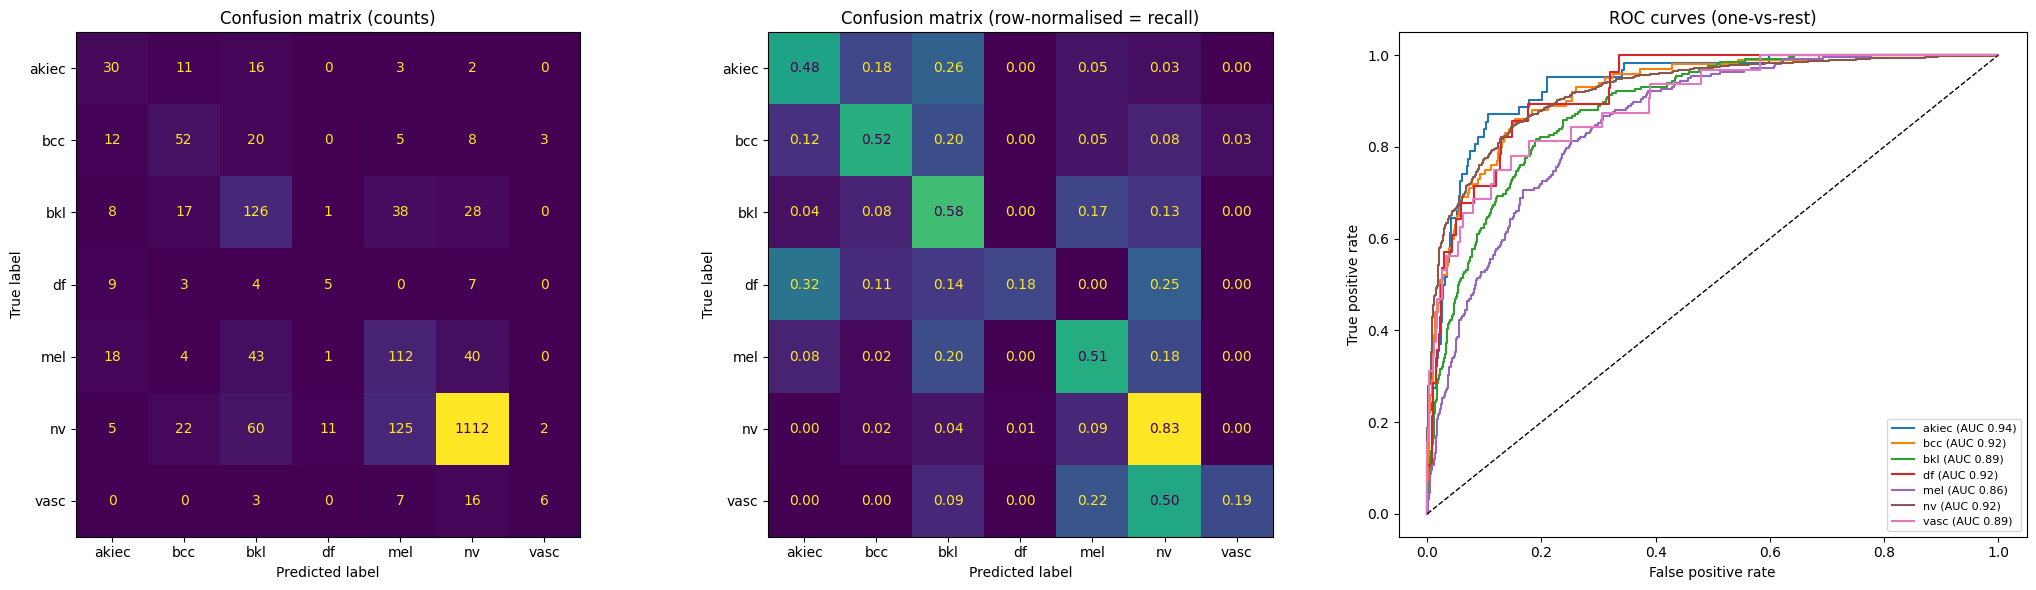

In [6]:
cols = feature_sets[best["Features"]]
final = models[best["Model"]]().fit(Xtr_f[:, cols], ytr)
pte = final.predict(Xte_f[:, cols]); proba = final.predict_proba(Xte_f[:, cols])

print(classification_report(yte, pte, target_names=classes, zero_division=0))

fig, ax = plt.subplots(1, 3, figsize=(21, 6))
ConfusionMatrixDisplay(confusion_matrix(yte, pte), display_labels=classes).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(yte, pte, normalize="true"), display_labels=classes)\
    .plot(ax=ax[1], colorbar=False, values_format=".2f")
ax[1].set_title("Confusion matrix (row-normalised = recall)")

Y = label_binarize(yte, classes=np.arange(len(classes)))
for k, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
    ax[2].plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.2f})")
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC curves (one-vs-rest)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "final_eval.png", dpi=200); plt.show()

## 6.5 Overfitting and underfitting analysis
Train vs cross-validated vs test macro-F1 for every model on the chosen feature set, with the train-test gap. Saved as `overfitting.png`. Logistic regression underfits (small gap, low scores); KNN, HistGradientBoosting and Random Forest overfit (large gaps). **Sheet item: interpret the results and say whether the model over- or underfits.**

                      Train F1  CV F1  Test F1  Train-Test gap
Model                                                         
Logistic Regression      0.455  0.424    0.417           0.038
KNN (k=15)               1.000  0.352    0.379           0.621
SVM (RBF)                0.598  0.453    0.438           0.160
Random Forest            0.836  0.461    0.464           0.371
HistGradientBoosting     0.925  0.509    0.463           0.462


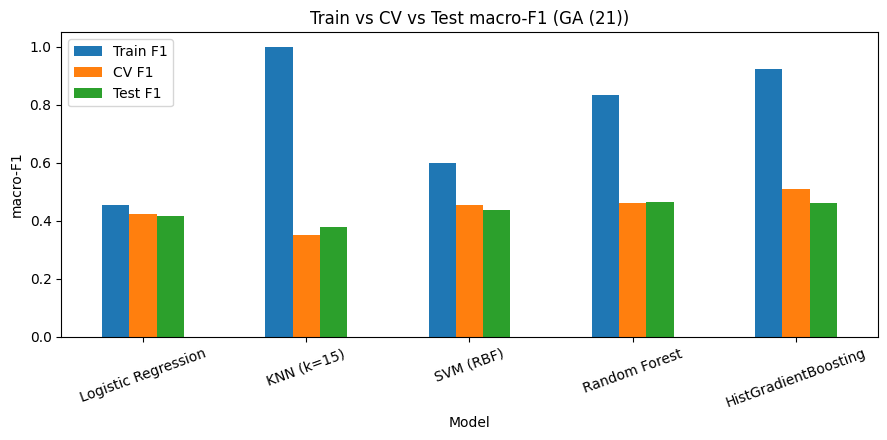

In [7]:
sub_ = res[res["Features"] == best["Features"]].set_index("Model")
tab = pd.DataFrame({"Train F1": sub_["Train F1 (macro)"], "CV F1": sub_["CV F1"], "Test F1": sub_["F1 (macro)"]})
tab["Train-Test gap"] = tab["Train F1"] - tab["Test F1"]
print(tab.round(3).to_string())

tab[["Train F1", "CV F1", "Test F1"]].plot.bar(figsize=(9, 4.5), rot=20)
plt.title(f"Train vs CV vs Test macro-F1 ({best['Features']})"); plt.ylabel("macro-F1")
plt.tight_layout(); plt.savefig(FIG / "overfitting.png", dpi=200); plt.show()

# End of notebook
The cell below is empty and can be deleted.

**Not in this notebook:** the written report, the related-work comparison table, the cover sheet and the optional bonus paper.